# End to End Anomaly detection using mix of data
# Using PCA and has LOF implemented as well
BGS data
This is the revised full RSEARCH VERSION of the proof of concept owrk done to detect anomalies. Will eventually have the proper normalisation etc in it. Will use data which has been processed by RESEARCH_VERSION_PREPROCESS_tf_dez_datasets.ipynb
OLD:Uses code blocks from tf_anomaly_detection_try1_qso_data.ipynb where the code is developed and uses data which has been deredshifted and downsampled in tf_dez_datasets.ipynb
xx

In [1]:
import datetime
now = datetime.datetime.now()
print("Version: " + now.strftime("%Y-%m-%d %H:%M:%S"))

Version: 2024-05-06 08:16:12


In [2]:
# Common imports
import numpy as np
import os
import tensorflow as tf
from tensorflow import keras

In [3]:
import pickle
from tqdm import tqdm
import copy
import corner

In [4]:
# to make this notebook's output stable across runs
def reset_state(seed=42):
    tf.keras.backend.clear_session()
    tf.random.set_seed(seed)
    np.random.seed(seed)

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

# Where to save the figures
try:
    import subprocess
    subprocess.run("git config --get remote.origin.url | grep 'astro-informatics'", shell=True, check=True)
    PROJECT_ROOT_DIR = "."
    CHAPTER_ID = "Lecture21_Images"
except: 
    PROJECT_ROOT_DIR = "."
    CHAPTER_ID = ""

def save_fig(fig_id, tight_layout=True):
    path = os.path.join(PROJECT_ROOT_DIR, CHAPTER_ID, fig_id + ".png")
#     print("Saving figure", fig_id)
#     if tight_layout:
#         plt.tight_layout()
#     plt.savefig(path, format='png', dpi=300)
    
def plot_image(image):
    plt.imshow(image, cmap="gray", interpolation="nearest")
    plt.axis("off")

def plot_color_image(image):
    plt.imshow(image.astype(np.uint8),interpolation="nearest")
    plt.axis("off")
    
import warnings
warnings.filterwarnings('ignore')

def plot_image(image, shape=[28, 28]):
    plt.imshow(image.reshape(shape), cmap="Greys", interpolation="nearest")
    plt.axis("off")



    
def plot_multiple_images(images, n_rows, n_cols, pad=2):
    images = images - images.min()  # make the minimum == 0, so the padding looks white
    w,h = images.shape[1:]
    image = np.zeros(((w+pad)*n_rows+pad, (h+pad)*n_cols+pad))
    for y in range(n_rows):
        for x in range(n_cols):
            image[(y*(h+pad)+pad):(y*(h+pad)+pad+h),(x*(w+pad)+pad):(x*(w+pad)+pad+w)] = images[y*n_cols+x]
    plt.imshow(image, cmap="Greys", interpolation="nearest")
    plt.axis("off")

# Loading in the DESI spectra
Based on the datasets which have been developed in tf_dez_datasets.ipynb we have 3 mixed datasets based on the BGS, ELG and QSO 10,000 spectra datasets we have set up spectra which have redshift ranges 0.2 to 1.4; 0.0 to 0.4; and 0.4 to 1.4.

## Run the block that you want and then you can follow through the analysis below for all of them

## Code block for BGSs z =0 to 0.04

In [5]:
#run_name = 'z 0.0 to 0.04'

In [6]:
#Running the combined data to see if it works
#reload object from file
#the no_zero version
#file2 = open(r'/pscratch/sd/u/ucaprpn/AssembledDatasets/de_z_spectra_z0_0to0_04_uni_iron_main_BGS_142617.pkl', 'rb')
#file3 = open(r'/pscratch/sd/u/ucaprpn/AssembledDatasets/de_z_spectra_z0_0to0_04_uni_iron_main_BGS_142617_wavelengths_2A.pkl', 'rb')
#file4 = open(r'/pscratch/sd/u/ucaprpn/AssembledDatasets/spectra_z0_0to0_04_uni_iron_main_BGS_142617.pkl', 'rb')
#loaded_de_z_spectra = pickle.load(file2)
#loaded_restframe_wavelengths = pickle.load(file3)
#loaded_original_spectra = pickle.load(file4)
#file2.close()
#file3.close()
#file4.close()

# Using a smaller block BGS data to get things working

In [5]:
run_name = 'z 0.0 to 0.02'

In [6]:
#reload object from file
#the no_zero version
file2 = open(r'/pscratch/sd/u/ucaprpn/AssembledDatasets/no_zero_de_z_spectra_z0_0to0_02_uni_iron_main_BGS_55293.pkl', 'rb')
#file2 = open(r'/pscratch/sd/u/ucaprpn/AssembledDatasets/de_z_spectra_z0_0to0_1_uni_iron_main_QSO_45479.pkl', 'rb')
file3 = open(r'/pscratch/sd/u/ucaprpn/AssembledDatasets/de_z_spectra_z0_0to0_02_uni_iron_main_BGS_55293_wavelengths_2A.pkl', 'rb')
file4 = open(r'/pscratch/sd/u/ucaprpn/AssembledDatasets/spectra_z0_0to0_02_uni_iron_main_BGS_55293.pkl', 'rb')
loaded_de_z_spectra = pickle.load(file2)
loaded_restframe_wavelengths = pickle.load(file3)
loaded_original_spectra = pickle.load(file4)
file2.close()
file3.close()
file4.close()

## Checking what's been loaded

In [7]:
print(f'Redshift range: {run_name}')
print(len(loaded_original_spectra))
print(len(loaded_de_z_spectra))
print(len(loaded_de_z_spectra[0]))
print(len(loaded_restframe_wavelengths))

Redshift range: z 0.0 to 0.02
55293
55293
2923
2923


In [8]:
loaded_original_spectra[0][1]

'BGS'

In [9]:
#This shows how to pull back the spectrum's spectype
loaded_original_spectra[0][0][4]

'STAR'

## Note: at some point we need to randomise this data in case there is structure within the data; but at the moment leave it untouched and everything is in the same order in the two file. And we check below to see what the distribution is and it's not terrible anyway.

## NOTE: In the research it says to:
* normalise
* mask the bad pixels
* Some other stuff - NEED TO CHECK RESEARCH

Not doing these things yet. The downsampling includes an element of denoising and normalisation

# ONCE WE HAVE SORTED OUT THE SHUFFLE WE WILL MOVE ALL PREPORCESSING OF THE DATA TO THE PIPELINE PROGRAM

# NEED TO ALSO EXPLICITLY INCLUDE THE SPECTRUM NUMBER SO WE CAN DO STUFF WITH IT LATER ON

## Building the training and validation sets

In [10]:
# Deredshifted and downsampled data

#As noted above need to be careful with numpy arrays; unless you make an explicit deep copy 
# you are always working on the orginal version of the file - and normal methods only work shallow so
#not good for lists 

# Note we still need to process the raw file as this has all the info on target ID, spectype etc



spectra_dez_ds = copy.deepcopy(loaded_de_z_spectra)


X_train_full_dez_ds = []

for i in tqdm(range(len(spectra_dez_ds))):
    spectra_flux = spectra_dez_ds[i]

    X_train_full_dez_ds.append(spectra_flux)             
    
X_train_full_array_dez_ds = np.array(X_train_full_dez_ds)

100%|██████████| 55293/55293 [00:00<00:00, 3707506.45it/s]


In [11]:
print(X_train_full_array_dez_ds.shape)

(55293, 2923)


In [12]:
# CHECKING ORDER HAS BEEN MAINTAINED
print(loaded_de_z_spectra[0:5])
print(X_train_full_array_dez_ds[0:5])

[array([ 0.42466283,  0.20877026, -1.82553661, ...,  6.83014154,
       -0.44644642,  4.0032661 ]), array([ 0.24924732, -0.93664106, -0.69654775, ..., 26.6445303 ,
       23.58545494, 26.16062355]), array([-5.48699665, -2.72894144, -5.73229563, ..., 22.10399437,
       32.28865687, 27.69247723]), array([21.51449394,  5.37162463,  4.48003292, ..., 35.67278481,
       43.77564748, 37.43706512]), array([ 1.8822211 ,  6.57371084,  5.69423148, ..., 26.34514332,
       22.16890685, 28.27153015])]
[[ 0.42466283  0.20877026 -1.82553661 ...  6.83014154 -0.44644642
   4.0032661 ]
 [ 0.24924732 -0.93664106 -0.69654775 ... 26.6445303  23.58545494
  26.16062355]
 [-5.48699665 -2.72894144 -5.73229563 ... 22.10399437 32.28865687
  27.69247723]
 [21.51449394  5.37162463  4.48003292 ... 35.67278481 43.77564748
  37.43706512]
 [ 1.8822211   6.57371084  5.69423148 ... 26.34514332 22.16890685
  28.27153015]]


# Further preprocessing of the data

## Normalisation
# WE WILL MOVE NNORMALISATION TO THE PIPELINE EVENTUALLY

To begin with let's just use the simple normalisation we had before which rescales each spectrum between 0 and 1

In [13]:
#Normalisation of the deredshifted and downshifted data
#Original version now commented took away the min and divided by the range
#Better version is to make the total add to 1, so add all fluxes and divide by this
#Note compared with tf_anomaly_detection_try1_qso_data.ipynb we don't need to do anything special with the windowing
# as noted above we've done that implicitly when we created the files so we don't need the _win subscripts that were
# in the earlier file.

X_train_full_dez_ds_norm = []

for i in tqdm(range(len(X_train_full_array_dez_ds))):
#for i in tqdm(range(5)):   
    
    spectra_flux = X_train_full_array_dez_ds[i]
#    print(spectra_flux)
    
#New Version 1 normalisation - just normalising dividing by the total flux did not work
#    total_flux = np.sum(spectra_flux)
#    normalised_spectra_flux = (spectra_flux)/(total_flux)

#New Version 2 normalisation rebase to zero and divide by total flux where we have also rebased to zero by subtracting min
#Kind of a cross between Version 1 and original
#    min = np.min(spectra_flux)
#    print(min)
#    total_flux = np.sum(spectra_flux-min)
#    print(total_flux)
#    normalised_spectra_flux = (spectra_flux)/(total_flux)
#    print(normalised_spectra_flux)
    
#New Version 3 divide by the average flux across the range. Still rebase to zero? Not sure
#Kind of a cross between Version 1 and original
#    mean_flux = np.mean(spectra_flux)
#    print(mean_flux)
#    normalised_spectra_flux = (spectra_flux)/(mean_flux)
#    print(normalised_spectra_flux)    

#Version 4 - No normalisation!! 
#    normalised_spectra_flux = spectra_flux

#Version 5 - even simpler normalisation: do not rebase to zero
#    max = np.max(spectra_flux)
#    min = np.min(spectra_flux)
#    normalised_spectra_flux = (spectra_flux)/(max - min)



#Simple normalisation - original    
    max = np.max(spectra_flux)
    min = np.min(spectra_flux)
    normalised_spectra_flux = (spectra_flux - min)/(max - min)
#use this to check there's no problem with the numbering
#    normalised_spectra_flux = spectra_flux
    
    X_train_full_dez_ds_norm.append(normalised_spectra_flux) 
# ADAPTING THE CODE TO EXPLICITLY BRING IN THE ORIGINAL SPECTRUM NUMBER
#    X_train_full_dez_ds_norm.append([normalised_spectra_flux,i]) 
# Doing it this way is icky as it introduces an array structure which tensorflow hates later on
    
X_train_full_array_dez_ds_norm = np.array(X_train_full_dez_ds_norm)
#print(X_train_full_array_dez_ds_norm)

100%|██████████| 55293/55293 [00:01<00:00, 49695.99it/s]


In [14]:
X_train_full_array_dez_ds_norm.shape

(55293, 2923)

# Setting up training and validation sets
# NOTE SHOULD PROBABLY DO SOME RANDOMISATION HERE - GIVEN THE WAY WE'VE BUILT THE DATA MIGHT BE PROBLEMATIC NOT TO DO THIS
# NEED TO THINK HOW TO DO THIS AS WE MIGHT MAKE USE OF THE INITIAL ORDER LATER ON...

In [15]:
#We want to put around 1/6 of the data into a validation set

len(X_train_full_array_dez_ds_norm)/6

9215.5

In [16]:
valid_size = 9000

# We're creating a custom routine to do the shuffling. To do it we're going to create an shuffled set of indices which tell give us the order of the shuffled spectra but which allow us to be able to get back to the original.

In [17]:
#THIS IS WHERE WE GOT TO. Let's use a custom routine to shuffle the data whilst also keeping track of the 
#order in which they've been shuffled.

#create an np array with all the numbers
ordered_indices = np.arange(len(loaded_original_spectra))


In [18]:
ordered_indices

array([    0,     1,     2, ..., 55290, 55291, 55292])

In [19]:
# Let's randomise the data using scikit-learn
from sklearn.utils import shuffle

In [20]:
shuffled_indices = shuffle(ordered_indices, random_state = 42)

In [21]:
print(shuffled_indices[0:10])
print(shuffled_indices[-10:])

[31175  9731 11658  1390 44403 44118 43257 29407 15267 54597]
[37194 16850  6265 54886 11284 44732 54343 38158   860 15795]


In [22]:
print(len(shuffled_indices))

55293


In [23]:
#Put ids into the training groups and the validation groups
X_train_ids, X_valid_ids = shuffled_indices[:(-1*valid_size)], shuffled_indices[(-1*valid_size):]

In [24]:
print(X_train_ids[0:10])
print(len(X_train_ids))
print(X_valid_ids[-10:])
print(X_valid_ids)
print(len(X_valid_ids))

[31175  9731 11658  1390 44403 44118 43257 29407 15267 54597]
46293
[37194 16850  6265 54886 11284 44732 54343 38158   860 15795]
[42012 47035 32317 ... 38158   860 15795]
9000


In [25]:
#This bit of code did not do what I expected it to do :( - ACTUALLY IT PROBABLY WORKED FINE!!! THE PROBLEM WAS SOMETHING ELSE
#X_train_dez_ds_norm = X_train_full_array_dez_ds_norm[X_train_ids]
#X_valid_dez_ds_norm = X_train_full_array_dez_ds_norm[X_valid_ids]
#So let's do this a more long winded way

X_train_intermediate = []
X_valid_intermediate = []

for p in tqdm(range(len(X_train_ids))):
    i = X_train_ids[p]  
    spectra_flux = X_train_full_array_dez_ds_norm[i]  
    X_train_intermediate.append(spectra_flux) 

for p in tqdm(range(len(X_valid_ids))):
    i = X_valid_ids[p]  
    spectra_flux = X_train_full_array_dez_ds_norm[i]  
    X_valid_intermediate.append(spectra_flux)     
    
X_train_dez_ds_norm = np.array(X_train_intermediate)
X_valid_dez_ds_norm = np.array(X_valid_intermediate)

print(len(X_train_dez_ds_norm))
print(len(X_valid_dez_ds_norm))


100%|██████████| 9000/9000 [00:00<00:00, 1596883.79it/s]


46293
9000


In [26]:
print(X_train_dez_ds_norm[0])

[0.16947236 0.29165207 0.65954341 ... 0.09178204 0.54075234 0.40856928]


In [27]:
print(X_train_dez_ds_norm)
print(X_train_dez_ds_norm.shape)
print(X_valid_dez_ds_norm)
print(X_valid_dez_ds_norm.shape)

[[0.16947236 0.29165207 0.65954341 ... 0.09178204 0.54075234 0.40856928]
 [0.13918994 0.59212192 1.         ... 0.48478646 0.35368102 0.44725627]
 [0.77447828 0.39346967 0.71103036 ... 0.42951895 0.31374652 0.26083506]
 ...
 [0.11792542 0.15887298 0.15793993 ... 0.15036146 0.1447167  0.14991565]
 [0.35585231 0.65564283 0.10183238 ... 0.10130492 0.27385313 0.14730871]
 [0.13701347 0.09583962 0.03769329 ... 0.12319551 0.12422698 0.10928707]]
(46293, 2923)
[[0.59063252 0.49606105 0.         ... 0.51485262 0.49029076 0.52372926]
 [0.14364363 0.7344066  0.82084684 ... 0.43230983 0.38364935 0.39474294]
 [0.07405842 0.08019652 0.05027058 ... 0.02815513 0.03184608 0.04111938]
 ...
 [0.23872569 0.03549742 0.2029857  ... 0.1477945  0.16085038 0.16354187]
 [0.46851013 0.55958523 0.         ... 0.54273252 0.61231163 0.52268278]
 [0.63327805 0.40916871 0.60598313 ... 1.         0.73548982 0.73099452]]
(9000, 2923)


In [28]:
# Do a quick check on how many QSOs there ought to be
len(loaded_original_spectra)


55293

In [29]:
#Checking how many of each spectype there were originally

STAR_count = 0
GALAXY_count = 0
QSO_count = 0

for i in range(len(loaded_original_spectra)):
    if loaded_original_spectra[i][0][4] == 'STAR': 
        STAR_count += 1

    if loaded_original_spectra[i][0][4] == 'GALAXY': 
        GALAXY_count += 1

    if loaded_original_spectra[i][0][4] == 'QSO': 
        QSO_count += 1
        
        
        
print(len(loaded_original_spectra))
print(STAR_count)
print(GALAXY_count)
print(QSO_count)

55293
32244
23049
0


In [24]:
#Superseded code
# NOTE:
# Keep the selection of the validation set size as manual at the moment so need to update this by hand
# *****************************************************************************************************


#X_train_dez_ds_norm, X_valid_dez_ds_norm = X_train_full_array_dez_ds_norm[:-7500], X_train_full_array_dez_ds_norm[-7500:]
#Adapted to take into account the shuffling
#X_train_dez_ds_norm, X_valid_dez_ds_norm = X_train_full_array_dez_ds_norm_shuffle[:-7500], X_train_full_array_dez_ds_norm_shuffle[-7500:]

In [30]:
print(X_train_dez_ds_norm.shape)
print(X_valid_dez_ds_norm.shape)

(46293, 2923)
(9000, 2923)


In [31]:
print(X_train_dez_ds_norm)

[[0.16947236 0.29165207 0.65954341 ... 0.09178204 0.54075234 0.40856928]
 [0.13918994 0.59212192 1.         ... 0.48478646 0.35368102 0.44725627]
 [0.77447828 0.39346967 0.71103036 ... 0.42951895 0.31374652 0.26083506]
 ...
 [0.11792542 0.15887298 0.15793993 ... 0.15036146 0.1447167  0.14991565]
 [0.35585231 0.65564283 0.10183238 ... 0.10130492 0.27385313 0.14730871]
 [0.13701347 0.09583962 0.03769329 ... 0.12319551 0.12422698 0.10928707]]


In [32]:
train_size = len(X_train_dez_ds_norm)
valid_size = len(X_valid_dez_ds_norm)

In [33]:
print(train_size)
print(valid_size)

46293
9000


In [34]:
# Accessing the original spectrum number of the spectrum

print(shuffled_indices[0])

31175


### #Check to see how representative the validation set is compared with the training set

In [35]:
#Adapted it so that it works on spectype rather than on survey
train_STAR = 0
train_GALAXY = 0
train_QSO = 0

train_STAR_list=[]
train_GALAXY_list=[]
train_QSO_list=[]

for p in range(len(X_train_dez_ds_norm)):
#FOR CHECKING SHUFFLING WORKING OK
#for p in range(1):    
    i = X_train_ids[p]
    
    if loaded_original_spectra[i][0][4] == 'STAR': 
        train_STAR += 1
        train_STAR_list.append(i)
    if loaded_original_spectra[i][0][4] == 'GALAXY': 
        train_GALAXY += 1
        train_GALAXY_list.append(i)
    if loaded_original_spectra[i][0][4] == 'QSO': 
        train_QSO += 1
        train_QSO_list.append(i)
        
        
print(f'STAR in training set= {train_STAR}')
print(len(train_STAR_list))
#print(train_STAR_list[0:10])
print(f'GALAXY in training set= {train_GALAXY}')
print(len(train_GALAXY_list))
#print(train_GALAXY_list)
print(f'QSO in training set= {train_QSO}')
print(len(train_QSO_list))


STAR in training set= 26921
26921
GALAXY in training set= 19372
19372
QSO in training set= 0
0


In [36]:
#Adapted it so that it works on spectype rather than on survey
#Check to see how representative the validation set is compared with the training set

valid_STAR = 0
valid_GALAXY = 0
valid_QSO = 0

valid_STAR_list=[]
valid_GALAXY_list=[]
valid_QSO_list=[]

for p in range(len(X_valid_dez_ds_norm)):
#FOR CHECKING SHUFFLING WORKING OK
#for p in range(1):
    
    i = X_valid_ids[p]
    
    if loaded_original_spectra[i][0][4] == 'STAR': 
        valid_STAR += 1
        valid_STAR_list.append(i)
    if loaded_original_spectra[i][0][4] == 'GALAXY': 
        valid_GALAXY += 1
        valid_GALAXY_list.append(i)
    if loaded_original_spectra[i][0][4] == 'QSO': 
        valid_QSO += 1
        valid_QSO_list.append(i)
        
        
print(f'STAR in validation set= {valid_STAR}')
#print(valid_STAR_list)
print(f'GALAXY in validation set= {valid_GALAXY}')
print(f'QSO in validation set= {valid_QSO}')

#print(f'BGS indices: {valid_bgs_list}')
#print(f'ELG indices: {valid_elg_list}')
#print(f'QSO indices: {valid_qso_list}')


STAR in validation set= 5323
GALAXY in validation set= 3677
QSO in validation set= 0


In [37]:
#Note we have already ensured that the window of wavelengths is consistent here for the redshift sample
#so we don't need to do anything extra here other than rename it
spectra_wavelengths_dez_ds = loaded_restframe_wavelengths
spectra_wavelengths_dez_ds.shape

(2923,)

In [38]:
num_bins = spectra_wavelengths_dez_ds.shape[0]
num_bins

2923

# THIS WAS ORIGINAL PROOF OF CONCEPT AUTOENCODER. WE DON'T WANT THIS BUT KEEP IN THERE FOR THE MOMENT IN CASE WE NEED TO CANNIBALISE CODE
# ************************************************

## Autoencoder

In [33]:
#Should be able to reuse the model from above but just to be on the safe side we will keep it separate
#THIS IS THE MODEL TO REFRESH

reset_state()

n_inputs_dez_ds_norm = 1 * len(spectra_wavelengths_dez_ds) #input dimension ds=downsampled

num_ecode_nodes = 6 #the number of dimensions in the latent layer

learning_rate = 0.01
l2_reg = 0.0001 #limit used in L2 reg

#Returns an initializer that generates tensors without scaling variance.
#When initializing a deep network, it is in principle advantageous to keep 
#the scale of the input variance constant, so it does not explode or 
#diminish by reaching the final layer. 
he_init = tf.keras.initializers.HeNormal() # He initialization

#Returns a function that can be used to apply L2 regularization to weights.
#Small values of L2 can help prevent overfitting the training data.
l2_regularizer = tf.keras.regularizers.L2(l2_reg)


In [34]:
# _dez_ds_norm - essentially still basing this heavily on the code from the lectures

def rounded_accuracy(y_true, y_pred):
    return keras.metrics.binary_accuracy(tf.round(y_true), tf.round(y_pred))

# Building a version which we can use for our spectra
tf.random.set_seed(42)
np.random.seed(42)

#Note slightly different form as no reshaping is required as the input is (None, 3000) rather than (None, 1, 3000)

# Has been working fine with activation=tf.keras.layers.ELU() but actually should use Leaky Relu, activation=tf.keras.layers.LeakyReLU(alpha=0.1)
# the alpha is the factor we are multimplying x by if it is negative.
# However when I try LeakyRelu it doesn't work so well and don't get good separation. So switch back to ELU


stacked_encoder_spectra_dez_ds_norm = keras.models.Sequential([
    keras.layers.Dropout(0.2),
    keras.layers.Dense(300, activation=tf.keras.layers.ELU(), kernel_initializer=he_init, kernel_regularizer=l2_regularizer, input_shape=[n_inputs_dez_ds_norm]),
    keras.layers.Dense(50, activation=tf.keras.layers.ELU(), kernel_initializer=he_init, kernel_regularizer=l2_regularizer),
    keras.layers.Dense(num_ecode_nodes, activation=tf.keras.layers.ELU(), kernel_initializer=he_init, kernel_regularizer=l2_regularizer),
])
stacked_decoder_spectra_dez_ds_norm = keras.models.Sequential([
    keras.layers.Dropout(0.2),
    keras.layers.Dense(50, activation=tf.keras.layers.ELU(), kernel_initializer=he_init, kernel_regularizer=l2_regularizer, input_shape=[num_ecode_nodes]),
    keras.layers.Dense(300, activation=tf.keras.layers.ELU(), kernel_initializer=he_init, kernel_regularizer=l2_regularizer),
    keras.layers.Dense(n_inputs_dez_ds_norm, activation="sigmoid"),
    
])
stacked_ae_spectra_dez_ds_norm = keras.models.Sequential([stacked_encoder_spectra_dez_ds_norm, stacked_decoder_spectra_dez_ds_norm])
#stacked_ae_spectra_dez_ds_norm_win.compile(loss=huber_fn,
#                   optimizer=keras.optimizers.SGD(lr=1.5), metrics=[rounded_accuracy])
stacked_ae_spectra_dez_ds_norm.compile(loss="mse",
                   optimizer=keras.optimizers.SGD(lr=1.5), metrics=[rounded_accuracy])

#Note have changed the loss function to mse - not a classification exercise so need to use an adjusted mse but mse will do for now

2024-04-26 03:53:10.756771: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-26 03:53:12.577296: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2350 MB memory:  -> device: 0, name: NVIDIA A100 80GB PCIe, pci bus id: 0000:c3:00.0, compute capability: 8.0


In [35]:

history_spectra_dez_ds_norm = stacked_ae_spectra_dez_ds_norm.fit(X_train_dez_ds_norm, X_train_dez_ds_norm, batch_size = 512, epochs= 50,
                         validation_data=(X_valid_dez_ds_norm, X_valid_dez_ds_norm))

Epoch 1/50
11/91 [==>...........................] - ETA: 0s - loss: 0.2140 - rounded_accuracy: 0.5022

2024-04-26 03:53:22.455350: I tensorflow/stream_executor/cuda/cuda_blas.cc:1786] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.


91/91 [==============================] - 6s 21ms/step - loss: 0.1996 - rounded_accuracy: 0.5311 - val_loss: 0.1846 - val_rounded_accuracy: 0.6367
Epoch 2/50
91/91 [==============================] - 1s 14ms/step - loss: 0.1713 - rounded_accuracy: 0.7106 - val_loss: 0.1537 - val_rounded_accuracy: 0.7610
Epoch 3/50
91/91 [==============================] - 2s 17ms/step - loss: 0.1487 - rounded_accuracy: 0.7939 - val_loss: 0.1377 - val_rounded_accuracy: 0.8495
Epoch 4/50
91/91 [==============================] - 1s 14ms/step - loss: 0.1370 - rounded_accuracy: 0.8210 - val_loss: 0.1287 - val_rounded_accuracy: 0.8229
Epoch 5/50
91/91 [==============================] - 2s 17ms/step - loss: 0.1277 - rounded_accuracy: 0.8391 - val_loss: 0.1195 - val_rounded_accuracy: 0.8864
Epoch 6/50
91/91 [==============================] - 1s 14ms/step - loss: 0.1198 - rounded_accuracy: 0.8527 - val_loss: 0.1130 - val_rounded_accuracy: 0.8537
Epoch 7/50
91/91 [==============================] - 2s 17ms/step - lo

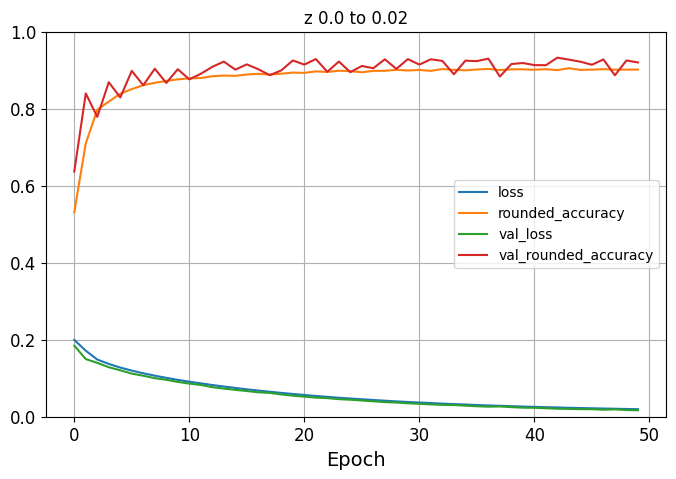

In [51]:
import pandas as pd
pd.DataFrame(history_spectra_dez_ds_norm.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.xlabel("Epoch")
plt.title(f'{run_name}')
plt.show()

## Checking an individual spectrum to see how good the reconstruction is
From here I originally did everything using the validation set but actually much better to use the training set for this as well so have doubled the code

In [ ]:
#Using the training set
reconstruction_dez_ds_norm = stacked_ae_spectra_dez_ds_norm.predict(X_train_dez_ds_norm)


#Using the Validation Dataset
#reconstruction_dez_ds_norm = stacked_ae_spectra_dez_ds_norm.predict(X_valid_dez_ds_norm)

In [ ]:
spectra_N = 8223

In [49]:
#Using the training set
spectra_flux_rec_dez_ds_norm = X_train_dez_ds_norm[spectra_N]

#Using the validation set
#spectra_flux_rec_dez_ds_norm = X_valid_dez_ds_norm[spectra_N]

In [50]:
spectra_reconstruction_dez_ds_norm = reconstruction_dez_ds_norm[spectra_N]

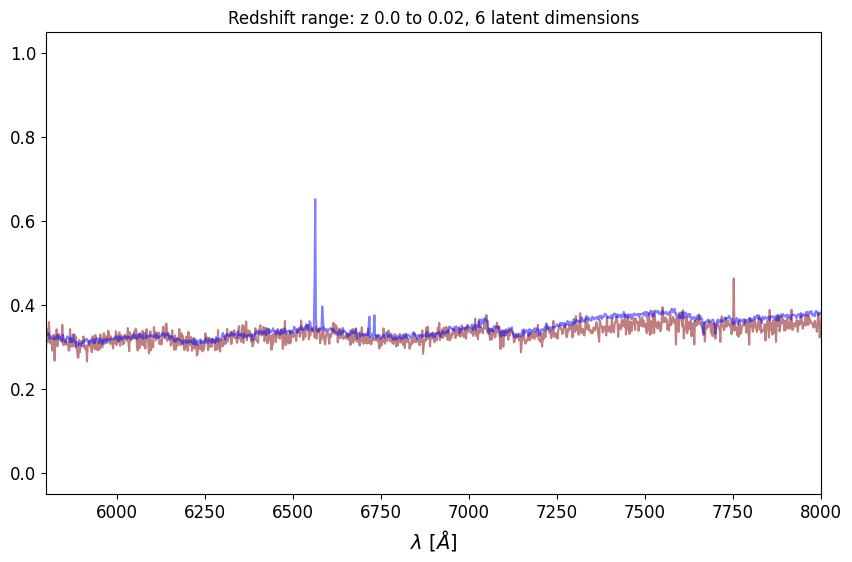

In [51]:
#Plotting these windowed spectra

plt.figure(figsize = (10, 6))
# Plot the deredshifted-downsampleds spectrum in maroon
plt.plot(loaded_restframe_wavelengths, spectra_flux_rec_dez_ds_norm, color = 'maroon', alpha = 0.5)

# Plot the reconstruction in blue
plt.plot(loaded_restframe_wavelengths, spectra_reconstruction_dez_ds_norm, color = 'blue', alpha = 0.5)


plt.xlim([5800, 8000])
#plt.ylim([0, 1.0])
plt.xlabel('$\lambda$ [$\AA$]')
# plt.ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
plt.title(f'Redshift range: {run_name}, {num_ecode_nodes} latent dimensions')

#plt.xticks(np.arange(4850, 4900, step=1), size = 8, rotation = 90)
#plt.grid(axis = 'x')

plt.show()

In [52]:
# And just to check we are not just reproducing the same thing every time for the reconstruction:


spectra_reconstruction_dez_ds_norm0 = reconstruction_dez_ds_norm[0]
spectra_reconstruction_dez_ds_norm1 = reconstruction_dez_ds_norm[20]
spectra_reconstruction_dez_ds_norm2 = reconstruction_dez_ds_norm[200]
spectra_reconstruction_dez_ds_norm3 = reconstruction_dez_ds_norm[1]
spectra_reconstruction_dez_ds_norm4 = reconstruction_dez_ds_norm[35]

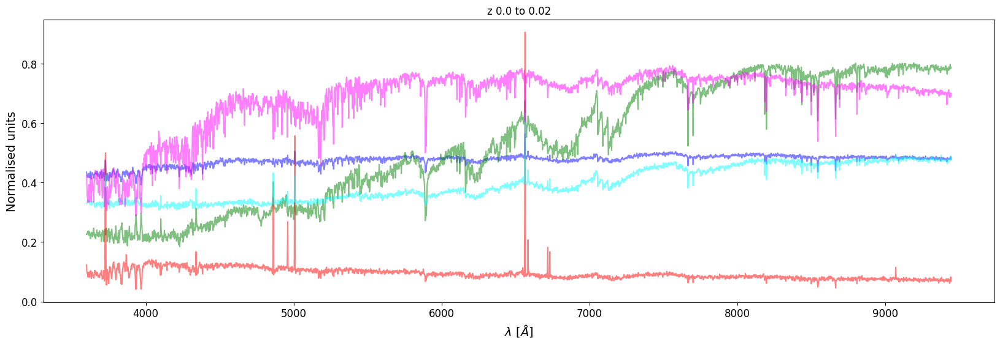

In [53]:
#Plotting these windowed reconstructed spectra

plt.figure(figsize = (20, 6))

plt.plot(loaded_restframe_wavelengths, spectra_reconstruction_dez_ds_norm0, color = 'blue', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, spectra_reconstruction_dez_ds_norm1, color = 'green', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, spectra_reconstruction_dez_ds_norm2, color = 'red', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, spectra_reconstruction_dez_ds_norm3, color = 'cyan', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, spectra_reconstruction_dez_ds_norm4, color = 'magenta', alpha = 0.5)

#plt.xlim([900, 2100])
#plt.ylim([0, 1.0])
plt.xlabel('$\lambda$ [$\AA$]')
plt.ylabel('Normalised units')
#plt.ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
plt.title(f'{run_name}')
plt.show()

# Calculating the mse loss

Note in the literature it's a little more sophisticated than this and that's fine - we can look at that in due course.

From the above we have X_valid_dez_ds_norm_win as our truth values and reconstruction_dez_ds_norm_win as the reconstructions. So just loop over them to get the mses

Used a code fragment from https://pyimagesearch.com/2020/03/02/anomaly-detection-with-keras-tensorflow-and-deep-learning/ which helped here

In [54]:
errors = []
# loop over all original spectra and their corresponding reconstructions

for i in tqdm(range(len(X_train_dez_ds_norm))):
    # compute the mean squared error between the ground-truth image
    # and the reconstructed image, then add it to our list of errors
    mse = np.mean((X_train_dez_ds_norm[i] - reconstruction_dez_ds_norm[i]) ** 2)
    errors.append(mse)






#for i in tqdm(range(len(X_valid_dez_ds_norm))):
    # compute the mean squared error between the ground-truth image
    # and the reconstructed image, then add it to our list of errors
#    mse = np.mean((X_valid_dez_ds_norm[i] - reconstruction_dez_ds_norm[i]) ** 2)
#    errors.append(mse)

100%|██████████| 46293/46293 [00:00<00:00, 92406.31it/s]


In [55]:
# Should be the length of the training or validation set - BUT ALSO SHOULD DO THIS WITH THE FULL TRAINIG SET AS WELL

print(len(errors))

46293


In [56]:
mean_error = np.mean(errors)
mean_error

0.004297078621458193

In [57]:
errors[spectra_N]

0.001895125388273693

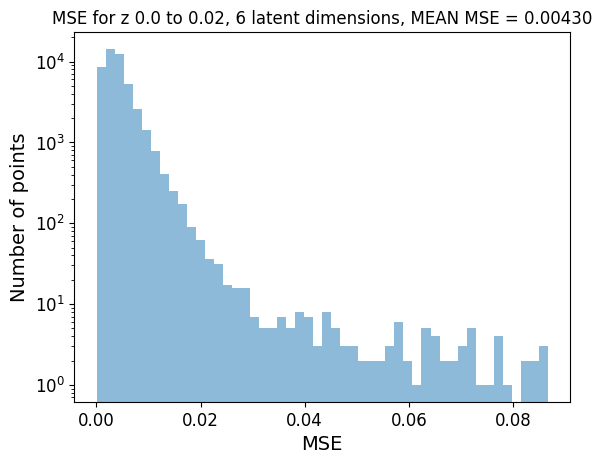

In [58]:
#Note density = False is a good setting as it means that each blob actually ties up with a point
count, bins, ignored = plt.hist(errors, 50, density=False, alpha=0.5)
plt.yscale('log')
plt.xlabel('MSE')
plt.ylabel('Number of points')
#plt.xlim([0.0,0.09])
plt.title(f'MSE for {run_name}, {num_ecode_nodes} latent dimensions, MEAN MSE = {mean_error:.5f}')
plt.show()

In [59]:
# Which ones are over a threshold, e.g. 0.04 Note we only picke up spectrum N=1 at >0.01

indices = np.where(np.array(errors) > 0.05)[0].tolist()
print(indices)
print(len(indices))

[1757, 2397, 3074, 3902, 3965, 4367, 4443, 4715, 5720, 6798, 7593, 7988, 9121, 9771, 10889, 13696, 13940, 14196, 15336, 16039, 16834, 17682, 18582, 23466, 23964, 26633, 26675, 27952, 28583, 29250, 31746, 33585, 33955, 33985, 34719, 34754, 35621, 36401, 38244, 38643, 38797, 38993, 39796, 40395, 40404, 41022, 41137, 42552, 44750, 44829, 45422, 45599, 46250]
53


In [60]:
# What were the original ids of these

In [61]:
# Which ones are below a threshold, e.g. 0.04 Note we only picke up spectrum N=1 at >0.01

indices_best = np.where(np.array(errors) < 0.00015)[0].tolist()
print(indices_best)

[572, 6017, 6251, 11569, 18374, 22906, 26428, 26484, 27860, 28343, 29897, 30196, 38558, 39455, 42014, 45736]


## NEED TO RUN THIS CODE BLOCK IF YOU'RE JUST DOING PCA AS WELL

## ********************************************

In [47]:
#Adapted to use spectype
errors_STAR_list = []
errors_GALAXY_list = []
errors_QSO_list = []

#This is creating lists with the ID within X_train_ids in it

for p in range(len(errors)):
#FOR CHECKING WHETHER INDEXING IS WORKING OK
#for p in range(1):
    i = X_train_ids[p]
    
    if loaded_original_spectra[i][0][4] == 'STAR': 
#        errors_STAR_list.append(i)
        errors_STAR_list.append(p)
    if loaded_original_spectra[i][0][4] == 'GALAXY': 
#        errors_GALAXY_list.append(i)
        errors_GALAXY_list.append(p)
    if loaded_original_spectra[i][0][4] == 'QSO':
#        errors_QSO_list.append(i)
        errors_QSO_list.append(p)

#print(errors_STAR_list)
#print(errors_GALAXY_list)
#print(errors_QSO_list)

NameError: name 'errors' is not defined

In [63]:
errors_STAR = np.array(errors)[errors_STAR_list]
errors_GALAXY = np.array(errors)[errors_GALAXY_list]
errors_QSO = np.array(errors)[errors_QSO_list]

In [64]:
print(len(errors_STAR))
print(len(errors_GALAXY))
print(len(errors_QSO))

26921
19372
0


In [65]:
print(errors_GALAXY[0])

0.0037313386464585137


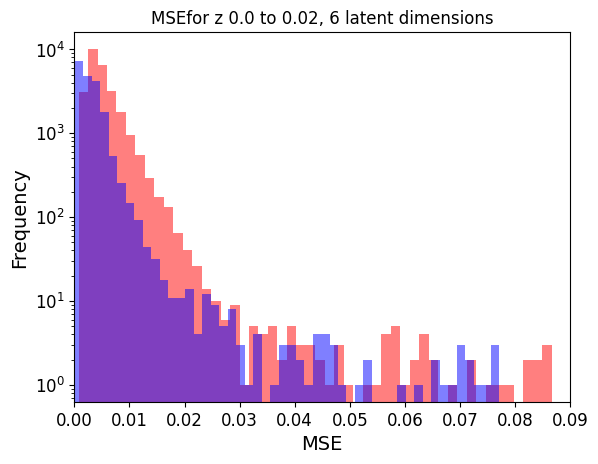

In [66]:
count, bins, ignored = plt.hist(errors_STAR, 50, density=False, alpha=0.5, color = 'red')
count, bins, ignored = plt.hist(errors_GALAXY, 50, density=False, alpha=0.5, color = 'blue')
count, bins, ignored = plt.hist(errors_QSO, 50, density=False, alpha=0.5, color = 'green')

plt.yscale('log')
plt.xlabel('MSE')
plt.ylabel('Frequency')
plt.xlim([0.0,0.09])
plt.title(f'MSEfor {run_name}, {num_ecode_nodes} latent dimensions')
plt.show()

In [67]:
# See if there are soem good quasars

indices_best_QSO = np.where(np.array(errors_QSO) < 0.0015)[0].tolist()
print(indices_best_QSO)

[]


In [68]:
#This gives the ids within the X_train_ids list
for index in indices_best_QSO:
    print(errors_QSO_list[index])
    

In [69]:
# See if there are soem good stars

indices_best_STAR = np.where(np.array(errors_STAR) < 0.001)[0].tolist()
print(indices_best_STAR)

[173, 5661, 6900, 11828]


In [70]:
#This gives the ids within the X_train_ids list
for index in indices_best_STAR:
    print(errors_STAR_list[index])

304
9718
11805
20223


In [91]:
#THE BEST 7 AND WORST 8
#int_spec = [572, 6017, 6251, 11569, 18374, 22906, 26428,304,9718,2397, 3965, 4443, 4715, 7988, 10889]

#The worst 51
int_spec = [572, 6017, 6251, 11569, 18374, 22906, 26428, 26484, 27860, 6798, 7593, 7988, 9121, 9771, 10889, 13696, 13940, 14196, 15336, 16039, 16834, 17682, 18582, 23466, 23964, 26633, 26675, 27952, 28583, 29250, 31746, 33585, 33955, 33985, 34719, 34754, 35621, 36401, 38244, 38643, 38797, 38993, 39796, 40395, 40404, 41022, 41137, 42552, 44750, 44829, 45422]

## Producing the latent layer

In [92]:
#Produce the latent representation using the encoder layer
#Using training dataset
latent_dez_ds_norm = stacked_encoder_spectra_dez_ds_norm.predict(X_train_dez_ds_norm)


#Using validation dataset
#latent_dez_ds_norm = stacked_encoder_spectra_dez_ds_norm.predict(X_valid_dez_ds_norm)

1447/1447 [==============================] - 1s 665us/step


## Plotting some interesting spectra - originals and reconstructions etc to eyeball what we are seeing

In [93]:
# As an aside look at the values in the latent layer:
for i in range (num_ecode_nodes):
    print(f'Dimension = {i}')
    for id in int_spec:
        print(f'For int_spec: {id} latent value is: {latent_dez_ds_norm[id][i]}')

Dimension = 0
For int_spec: 572 latent value is: 3.7889902591705322
For int_spec: 6017 latent value is: 4.0432305335998535
For int_spec: 6251 latent value is: 3.897265672683716
For int_spec: 11569 latent value is: 4.001094818115234
For int_spec: 18374 latent value is: 3.9053666591644287
For int_spec: 22906 latent value is: 3.783806562423706
For int_spec: 26428 latent value is: 3.980365514755249
For int_spec: 26484 latent value is: 3.7908565998077393
For int_spec: 27860 latent value is: 3.8856213092803955
For int_spec: 6798 latent value is: -0.860887348651886
For int_spec: 7593 latent value is: -0.8378213047981262
For int_spec: 7988 latent value is: -0.8950275182723999
For int_spec: 9121 latent value is: -0.8587651252746582
For int_spec: 9771 latent value is: -0.8593721985816956
For int_spec: 10889 latent value is: -0.8886509537696838
For int_spec: 13696 latent value is: -0.8422313928604126
For int_spec: 13940 latent value is: -0.8386725783348083
For int_spec: 14196 latent value is: -0.

In [94]:
# Pulling back the Target Ids. If using the validation set then need to use the lines adding the train_size 
#THIS IS AN AREA WHERE WE RELY ON THE ORDER AND HENCE NEED TO BE CAREFUL HOW WE DO THE RANDOMISATION

t_ids = []
z_vals = []
spec_types = []
desi_types =[]
mse_for_sample =[]

for p in int_spec:
    num = X_train_ids[p]
    
    t_ids.append(loaded_original_spectra[num][0][0])
    #t_ids.append(loaded_original_spectra[train_size+num][0][0])
    z_vals.append(loaded_original_spectra[num][0][3])
    #z_vals.append(loaded_original_spectra[train_size+num][0][3])
    spec_types.append(loaded_original_spectra[num][0][4])
    #spec_types.append(loaded_original_spectra[train_size+num][0][4])
    desi_types.append(loaded_original_spectra[num][1])
    #desi_types.append(loaded_original_spectra[train_size+num][1])
    mse_for_sample.append(errors[p])

print(t_ids)
print(z_vals)
print(spec_types)
print(desi_types)
print(mse_for_sample)

[39633063856047428, 39627606454178792, 39633285453710923, 39627785060229031, 39627936273273894, 39627601228073622, 39628276439714818, 39627624456129362, 39633285495654508, 39627892677673253, 39627444516292401, 39628135892779615, 39627959396470598, 39627719524226688, 39627661173064053, 39627765741260193, 39627989347991728, 39628065248124074, 39627577240849852, 39627802105876433, 39633148077672422, 39632981341504209, 39633073184181002, 39627832187429468, 39627783881628319, 39627591132384034, 39627627509581524, 39627899866710229, 39627567220659799, 39636761487345137, 39627829259796823, 39628064908382693, 39627577236656504, 39633267028133651, 39633167103034442, 39627589194617289, 39628290968783270, 39633123574551920, 39628059329960396, 39627826281843841, 39627678235495666, 39632976312535727, 39627627346003947, 39628129731347078, 39628193900004287, 39627844816477151, 39627902630759483, 39628257062031111, 39627589207196365, 39627526078727592, 39633387790533427]
[0.015537059728262125, 0.01972

### a) Original Spectra

In [95]:
# Plotting a particular spectrum first

In [96]:
spectra_wavelengths_raw = loaded_original_spectra[0][0][6]['brz']

In [97]:
spectra_wavelengths_raw.shape

(7781,)

In [98]:
print(spectra_wavelengths_raw[6700:6900])

[8960.  8960.8 8961.6 8962.4 8963.2 8964.  8964.8 8965.6 8966.4 8967.2
 8968.  8968.8 8969.6 8970.4 8971.2 8972.  8972.8 8973.6 8974.4 8975.2
 8976.  8976.8 8977.6 8978.4 8979.2 8980.  8980.8 8981.6 8982.4 8983.2
 8984.  8984.8 8985.6 8986.4 8987.2 8988.  8988.8 8989.6 8990.4 8991.2
 8992.  8992.8 8993.6 8994.4 8995.2 8996.  8996.8 8997.6 8998.4 8999.2
 9000.  9000.8 9001.6 9002.4 9003.2 9004.  9004.8 9005.6 9006.4 9007.2
 9008.  9008.8 9009.6 9010.4 9011.2 9012.  9012.8 9013.6 9014.4 9015.2
 9016.  9016.8 9017.6 9018.4 9019.2 9020.  9020.8 9021.6 9022.4 9023.2
 9024.  9024.8 9025.6 9026.4 9027.2 9028.  9028.8 9029.6 9030.4 9031.2
 9032.  9032.8 9033.6 9034.4 9035.2 9036.  9036.8 9037.6 9038.4 9039.2
 9040.  9040.8 9041.6 9042.4 9043.2 9044.  9044.8 9045.6 9046.4 9047.2
 9048.  9048.8 9049.6 9050.4 9051.2 9052.  9052.8 9053.6 9054.4 9055.2
 9056.  9056.8 9057.6 9058.4 9059.2 9060.  9060.8 9061.6 9062.4 9063.2
 9064.  9064.8 9065.6 9066.4 9067.2 9068.  9068.8 9069.6 9070.4 9071.2
 9072.

In [99]:
original_ID = X_train_ids[spectra_N]
original_ID

8931

In [100]:
original_ID = X_train_ids[spectra_N]
original_ID

8931

In [101]:
#CHECKING THAT THE SPECTRA ARE INDEED NORMALISED
#X_train_ids 29805
#original_ID_1 = X_train_ids[29805]
#print(original_ID_1)

#spectrum_check = loaded_original_spectra[original_ID_1][0][7]['brz'].flatten()
#print(len(spectrum_check))
#print(np.mean(spectrum_check))
#print(spectrum_check)

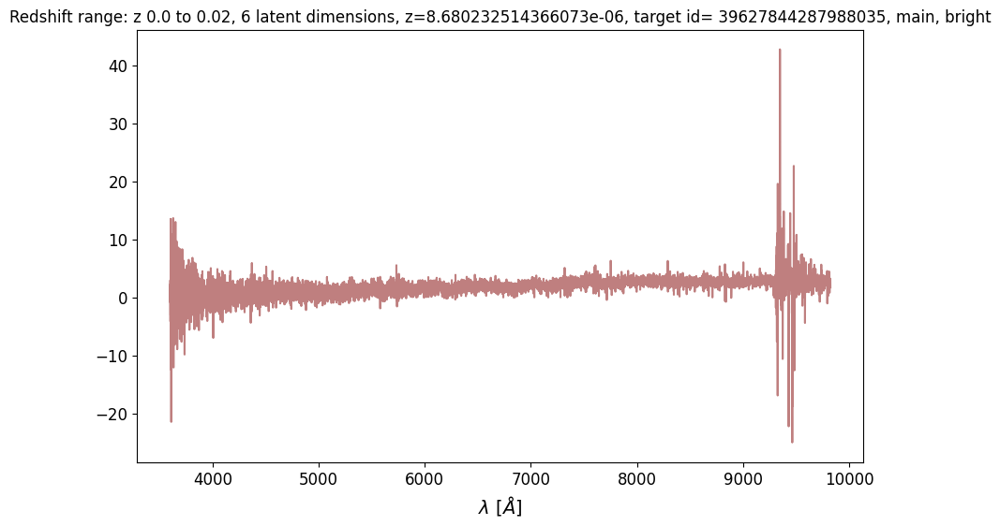

In [102]:
#Plotting the original spectrum of spectra_N

original_ID = X_train_ids[spectra_N]
#original_ID = 10035

redshift = loaded_original_spectra[original_ID][0][3]
t_id = loaded_original_spectra[original_ID][0][0]
survey = loaded_original_spectra[original_ID][0][1]
program = loaded_original_spectra[original_ID][0][2]

#redshift = loaded_original_spectra[spectra_N][0][3]
#t_id = loaded_original_spectra[spectra_N][0][0]
#survey = loaded_original_spectra[spectra_N][0][1]
#program = loaded_original_spectra[spectra_N][0][2]

plt.figure(figsize = (10, 6))
# Plot the deredshifted-downsampleds spectrum in maroon
plt.plot(spectra_wavelengths_raw, loaded_original_spectra[original_ID][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
#plt.plot(spectra_wavelengths_raw, loaded_original_spectra[spectra_N][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)


#plt.xlim([4200, 8400])
#plt.ylim([-5, 10.0])
plt.xlabel('$\lambda$ [$\AA$]')
# plt.ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
plt.title(f'Redshift range: {run_name}, {num_ecode_nodes} latent dimensions, z={redshift}, target id= {t_id}, {survey}, {program}')

#plt.xticks(np.arange(9017, 9020, step=0.1), size = 8, rotation = 90)

#plt.grid(axis = 'x')

plt.show()

In [103]:
# quite a painful bit of manipulation required to make sure the spectra in in consistent shape
#If using validation data need to use the version which adds in the train_size

loaded_original_spectra[int_spec[0]][0][7]['brz'].flatten().shape
#loaded_original_spectra[train_size+int_spec[0]][0][6]['brz'].flatten().shape

(7781,)

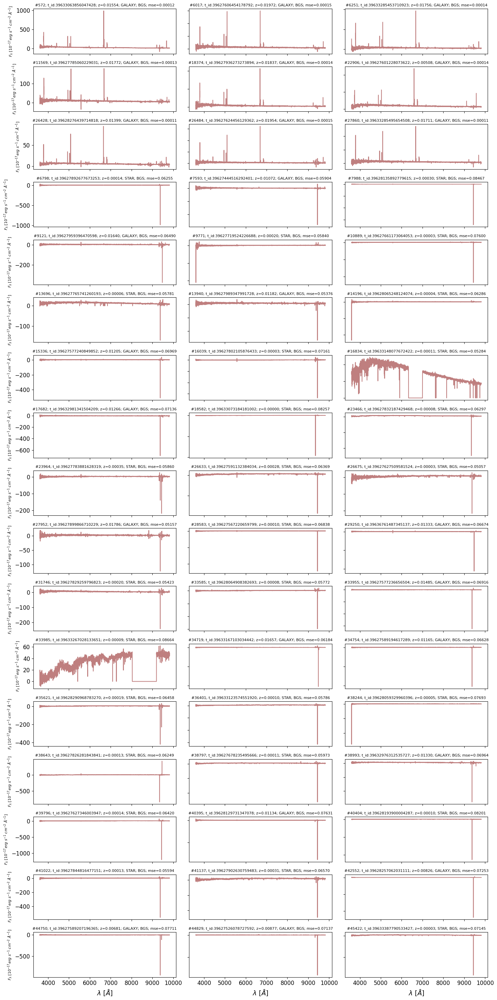

In [104]:
#if using the validation set need to use the version which adds in the train size

#figure, axis = plt.subplots(5, 3, figsize=(15, 12))

#if using 21
#figure, axis = plt.subplots(7, 3, figsize=(15, 18)) #in fig size it is (x, y) width v height

#if using 51
figure, axis = plt.subplots(17, 3, figsize=(15, 30)) #in fig size it is (x, y) width v height

for i in range(len(int_spec)):
    axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[X_train_ids[int_spec[i]]][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
#    axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[int_spec[i]][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
    #axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[train_size+int_spec[i]][0][6]['brz'].flatten(), color = 'maroon', alpha = 0.5)
    axis[i // 3, i % 3].set_title(f'#{int_spec[i]}; t_id:{t_ids[i]}; z={z_vals[i]:.5f}; {spec_types[i]}; {desi_types[i]}; mse={mse_for_sample[i]:.5f}', size = 8)
    


for ax in axis.flat:
    #ax.set(xlabel='$\lambda$ [$\AA$]', ylabel=('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
    ax.set_xlabel('$\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]', fontsize = 8)
   


# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
#figure.suptitle(f'Original spectra (8 worst, 7 best (any) and best QSO MSE) sample using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}', fontweight="bold", size =16)

plt.tight_layout()
plt.show()

In [105]:
#Translating a single ID to be used elsewhere
orig_ID = X_train_ids[38098]
print(orig_ID)

42385


## Reconstructed Spectra overlaid onto original spectra

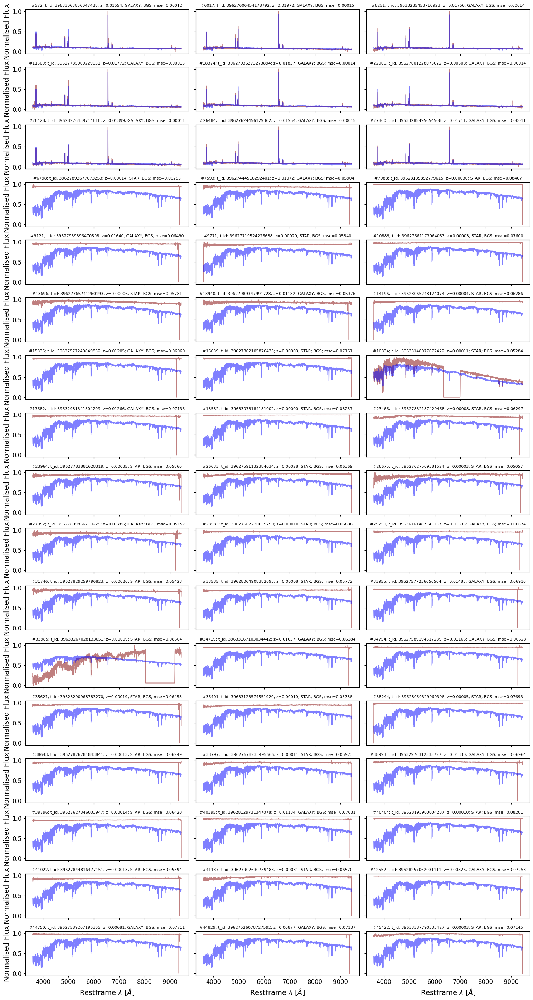

In [106]:
#if using the validation set need to use the version which adds in the train size


#figure, axis = plt.subplots(5, 3, figsize=(15, 12))

#if using 21
#figure, axis = plt.subplots(7, 3, figsize=(15, 18)) #in fig size it is (x, y) width v height

#if using 51
figure, axis = plt.subplots(17, 3, figsize=(15, 28)) #in fig size it is (x, y) width v height


for i in range(len(int_spec)):
    axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_train_dez_ds_norm[int_spec[i]], color = 'maroon', alpha = 0.5)
    #axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_valid_dez_ds_norm[int_spec[i]], color = 'maroon', alpha = 0.5)
    
    axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, reconstruction_dez_ds_norm[int_spec[i]], color = 'blue', alpha = 0.5)
    
    axis[i // 3, i % 3].set_title(f'#{int_spec[i]}; t_id: {t_ids[i]}; z={z_vals[i]:.5f}; {spec_types[i]}; {desi_types[i]}; mse={mse_for_sample[i]:.5f}',  size = 8)

for ax in axis.flat:
    #ax.set(xlabel='$\lambda$ [$\AA$]', ylabel='$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
    ax.set_xlabel('Restframe $\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('Normalised Flux', fontsize = 14)

# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
#figure.suptitle(f'10 worst, 4 best (outright) and best QSO MSE spectra using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}',fontweight = 'bold', size =16)
plt.tight_layout()
plt.show()

## Examining the latent layer

In [107]:
print(latent_dez_ds_norm.shape)
print(latent_dez_ds_norm[0])

(46293, 6)
[ 0.15752453 -0.2167102   0.20718631  0.18692291 -0.43135995  0.16996872]


In [108]:
lat_0 = latent_dez_ds_norm[:,0]
lat_1 = latent_dez_ds_norm[:,1]
lat_2 = latent_dez_ds_norm[:,2]
lat_3 = latent_dez_ds_norm[:,3]
lat_4 = latent_dez_ds_norm[:,4]
lat_5 = latent_dez_ds_norm[:,5]
#lat_6 = latent_dez_ds_norm[:,6]
#lat_7 = latent_dez_ds_norm[:,7]
#lat_8 = latent_dez_ds_norm[:,8]
#lat_9 = latent_dez_ds_norm[:,9]


In [109]:
#Change as required
dimx = 2
dimy = 3

x_data = lat_2
y_data = lat_3

########




x_data_STAR = x_data[errors_STAR_list]
y_data_STAR = y_data[errors_STAR_list]
x_data_GALAXY = x_data[errors_GALAXY_list]
y_data_GALAXY = y_data[errors_GALAXY_list]
x_data_QSO = x_data[errors_QSO_list]
y_data_QSO = y_data[errors_QSO_list]


In [110]:
x_mean = x_data.mean()
y_mean = y_data.mean()

x_mean_STAR = x_data_STAR.mean()
y_mean_STAR = y_data_STAR.mean()
x_mean_GALAXY = x_data_GALAXY.mean()
y_mean_GALAXY = y_data_GALAXY.mean()
x_mean_QSO = x_data_QSO.mean()
y_mean_QSO = y_data_QSO.mean()


In [111]:
print(x_mean)
print(y_mean)

0.49373674
0.47389007


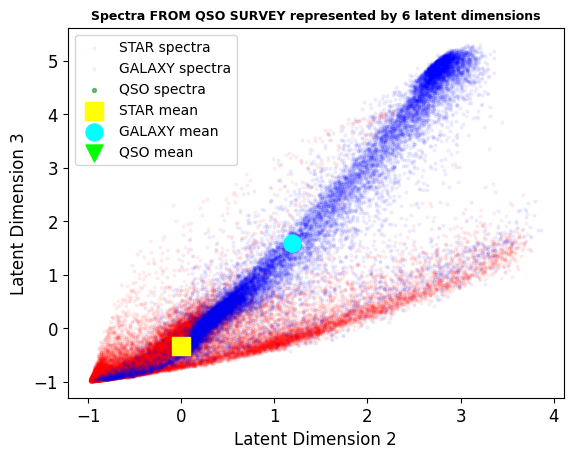

In [112]:

#plt.scatter(x_data, y_data, color = 'red', alpha =0.5, s= 4)
plt.scatter(x_data_STAR, y_data_STAR, color = 'red', alpha =0.05, s= 4)
plt.scatter(x_data_GALAXY, y_data_GALAXY, color = 'blue', alpha =0.05, s= 4)
plt.scatter(x_data_QSO, y_data_QSO, color = 'green', alpha =0.5, s= 8)

#plt.scatter(x_mean, y_mean, color = 'yellow', alpha =1.0, marker = 's', s= 150)
plt.scatter(x_mean_STAR, y_mean_STAR, color = 'yellow', alpha =1.0, marker = 's', s= 150)
plt.scatter(x_mean_GALAXY, y_mean_GALAXY, color = 'cyan', alpha =1.0, marker = 'o', s=150)
plt.scatter(x_mean_QSO, y_mean_QSO, color = 'lime', alpha =1.0, marker = 'v', s= 150)


plt.xlabel(f'Latent Dimension {dimx}', size = 12)
plt.ylabel(f'Latent Dimension {dimy}', size = 12)

plt.legend(['STAR spectra','GALAXY spectra','QSO spectra','STAR mean','GALAXY mean','QSO mean'])

plt.title(f'Spectra FROM QSO SURVEY represented by {num_ecode_nodes} latent dimensions', size = 9, fontweight = 'bold')

plt.show()

### Lets visualise the mean spectra for each SPECtype

### Note: rather using the mean spectrum as the starting point take a well fitting real spectrum from the centre and see what happens as you flex the dimensions - that should avoid the weird tail issue below

In [113]:
latent_dez_ds_norm_STAR = latent_dez_ds_norm[errors_STAR_list]
latent_dez_ds_norm_GALAXY = latent_dez_ds_norm[errors_GALAXY_list]
latent_dez_ds_norm_QSO = latent_dez_ds_norm[errors_QSO_list]

latent_dez_ds_norm_STAR_mean = np.mean(latent_dez_ds_norm_STAR, axis = 0)
latent_dez_ds_norm_GALAXY_mean = np.mean(latent_dez_ds_norm_GALAXY, axis = 0)
latent_dez_ds_norm_QSO_mean = np.mean(latent_dez_ds_norm_QSO, axis = 0)

print(f'STAR Mean: {latent_dez_ds_norm_STAR_mean}')
print(f'GALAXY Mean: {latent_dez_ds_norm_GALAXY_mean}')
print(f'QSO Mean: {latent_dez_ds_norm_QSO_mean}')


STAR Mean: [-0.2632031  -0.37651777 -0.00388617 -0.3376191   1.6095651   0.65815103]
GALAXY Mean: [ 1.5331304   1.1030747   1.1852764   1.6016351  -0.1671708   0.02214238]
QSO Mean: [nan nan nan nan nan nan]


In [114]:
# Need to reshape as the decoder is expecting it to be (1, 6) in shape
latent_dez_ds_norm_STAR_mean_T = latent_dez_ds_norm_STAR_mean.reshape(1,num_ecode_nodes)
latent_dez_ds_norm_GALAXY_mean_T = latent_dez_ds_norm_GALAXY_mean.reshape(1,num_ecode_nodes)
latent_dez_ds_norm_QSO_mean_T = latent_dez_ds_norm_QSO_mean.reshape(1,num_ecode_nodes)

In [115]:
# Let's put these through the decoder to see what the mean spectra look like

latent_dez_ds_norm_STAR_mean_spec = stacked_decoder_spectra_dez_ds_norm.predict(latent_dez_ds_norm_STAR_mean_T)
latent_dez_ds_norm_GALAXY_mean_spec = stacked_decoder_spectra_dez_ds_norm.predict(latent_dez_ds_norm_GALAXY_mean_T)
latent_dez_ds_norm_QSO_mean_spec = stacked_decoder_spectra_dez_ds_norm.predict(latent_dez_ds_norm_QSO_mean_T)

1/1 [==============================] - 0s 27ms/step


In [116]:
# But these need to be reshaped back again - aaah!
latent_dez_ds_norm_STAR_mean_spec_r = latent_dez_ds_norm_STAR_mean_spec.reshape(num_bins)
latent_dez_ds_norm_GALAXY_mean_spec_r = latent_dez_ds_norm_GALAXY_mean_spec.reshape(num_bins)
latent_dez_ds_norm_QSO_mean_spec_r = latent_dez_ds_norm_QSO_mean_spec.reshape(num_bins)


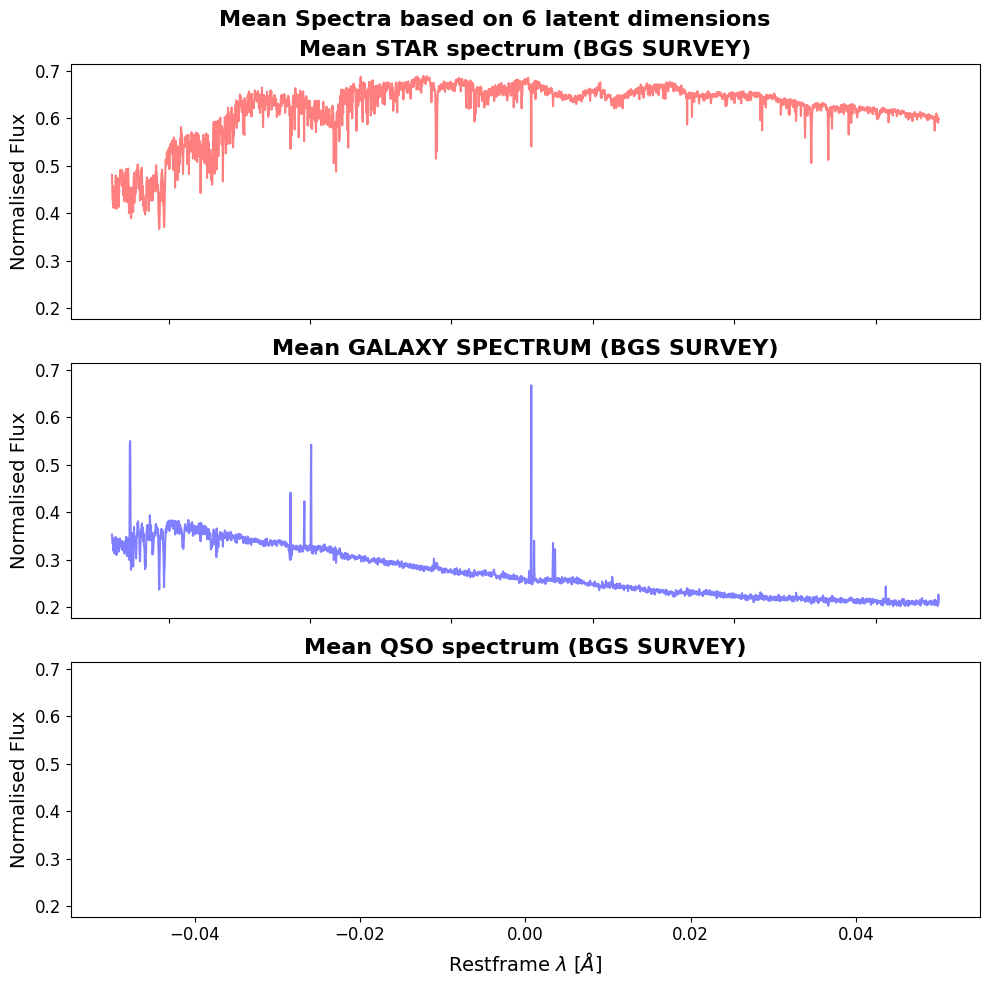

In [117]:
# sharey = True means we will share the y axes for all the plots
figure, axis = plt.subplots(3, 1, figsize=(10, 10), sharey = True)


axis[0].plot(loaded_restframe_wavelengths, latent_dez_ds_norm_STAR_mean_spec_r, color = 'red', alpha = 0.5)
axis[0].set_title(f'Mean STAR spectrum (BGS SURVEY)', size =16, fontweight = 'bold')

axis[1].plot(loaded_restframe_wavelengths, latent_dez_ds_norm_GALAXY_mean_spec_r, color = 'blue', alpha = 0.5)
axis[1].set_title(f'Mean GALAXY SPECTRUM (BGS SURVEY)', size =16, fontweight = 'bold')

axis[2].plot(loaded_restframe_wavelengths, latent_dez_ds_norm_QSO_mean_spec_r, color = 'green', alpha = 0.5)
axis[2].set_title(f'Mean QSO spectrum (BGS SURVEY)', size =16, fontweight = 'bold')
    


for ax in axis.flat:

    ax.set_xlabel('Restframe $\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('Normalised Flux', fontsize = 14)

# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
figure.suptitle(f'Mean Spectra based on {num_ecode_nodes} latent dimensions',fontweight = 'bold', size =16)
plt.tight_layout()
plt.show()

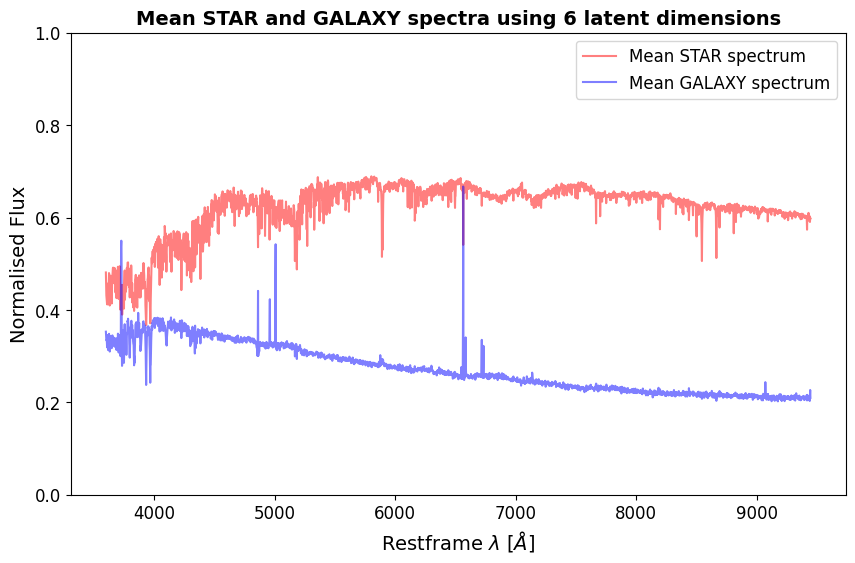

In [188]:
# And low let's also plot all three spectra on the same chart

#Plotting these windowed reconstructed spectra

plt.figure(figsize = (10, 6))

plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_STAR_mean_spec_r, color = 'red', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_GALAXY_mean_spec_r, color = 'blue', alpha = 0.5)
#plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_QSO_mean_spec_r, color = 'green', alpha = 0.5)

#plt.legend(['Mean STAR spectrum','Mean GALAXY spectrum','Mean QSO spectrum'], fontsize = 20)
plt.legend(['Mean STAR spectrum','Mean GALAXY spectrum'], fontsize = 12)

#plt.xlim([900, 2100])
plt.ylim([0, 1.0])
plt.xlabel('Restframe $\lambda$ [$\AA$]')
plt.ylabel('Normalised Flux')
#plt.title(f'Mean STAR, GALAXY and QSO spectra using {num_ecode_nodes} latent dimensions', fontweight = 'bold', size =16)
plt.title(f'Mean STAR and GALAXY spectra using {num_ecode_nodes} latent dimensions', fontweight = 'bold', size =14)
plt.show()

# xxxxxxxxxxxxxxxxxx
# HAVE NOT UPDATED THIS - IGNORE UNTIL STOP IGNORing
# xxxxxxxxxxxxxxxx

In [66]:
# Manually moving across the latnt space in dimension 3 - increases height of the spectrum
lat_d = 3
latent_dez_ds_norm_bgs_mean_1_0 = np.array([ 0.07744164,  0.6508763,   0.05608363,  1.0,  -0.26098162, -0.03033229])
latent_dez_ds_norm_bgs_mean_1_5 = np.array([ 0.07744164,  0.6508763,   0.05608363,  1.5,  -0.26098162, -0.03033229])
latent_dez_ds_norm_bgs_mean_2_0 = np.array([ 0.07744164,  0.6508763,   0.05608363,  2.0,  -0.26098162, -0.03033229])


In [67]:
# Manually moving across the latnt space in dimension 4
lat_d = 4
latent_dez_ds_norm_bgs_mean_1_0 = np.array([ 0.07744164,  0.6508763,   0.05608363,  0.4290601,  0.0, -0.03033229])
latent_dez_ds_norm_bgs_mean_1_5 = np.array([ 0.07744164,  0.6508763,   0.05608363,  0.4290601,  0.5, -0.03033229])
latent_dez_ds_norm_bgs_mean_2_0 = np.array([ 0.07744164,  0.6508763,   0.05608363,  0.4290601,  1.0, -0.03033229])

In [68]:
# Need to reshape as the decoder is expecting it to be (1, 6) in shape
latent_dez_ds_norm_bgs_mean_1_0_T = latent_dez_ds_norm_bgs_mean_1_0.reshape(1,num_ecode_nodes)
latent_dez_ds_norm_bgs_mean_1_5_T = latent_dez_ds_norm_bgs_mean_1_5.reshape(1,num_ecode_nodes)
latent_dez_ds_norm_bgs_mean_2_0_T = latent_dez_ds_norm_bgs_mean_2_0.reshape(1,num_ecode_nodes)

In [69]:
# Let's put these through the decoder to see what the mean spectra look like

latent_dez_ds_norm_bgs_mean_1_0_spec = stacked_decoder_spectra_dez_ds_norm.predict(latent_dez_ds_norm_bgs_mean_1_0_T)
latent_dez_ds_norm_bgs_mean__1_5_spec = stacked_decoder_spectra_dez_ds_norm.predict(latent_dez_ds_norm_bgs_mean_1_5_T)
latent_dez_ds_norm_bgs_mean__2_0_spec = stacked_decoder_spectra_dez_ds_norm.predict(latent_dez_ds_norm_bgs_mean_2_0_T)

1/1 [==============================] - 0s 35ms/step


In [130]:
# But these need to be reshaped back again - aaah!
latent_dez_ds_norm_bgs_mean_1_0_spec_r = latent_dez_ds_norm_bgs_mean_1_0_spec.reshape(num_bins)
latent_dez_ds_norm_bgs_mean__1_5_spec_r = latent_dez_ds_norm_bgs_mean__1_5_spec.reshape(num_bins)
latent_dez_ds_norm_bgs_mean__2_0_spec_r = latent_dez_ds_norm_bgs_mean__2_0_spec.reshape(num_bins)


NameError: name 'latent_dez_ds_norm_bgs_mean_1_0_spec' is not defined

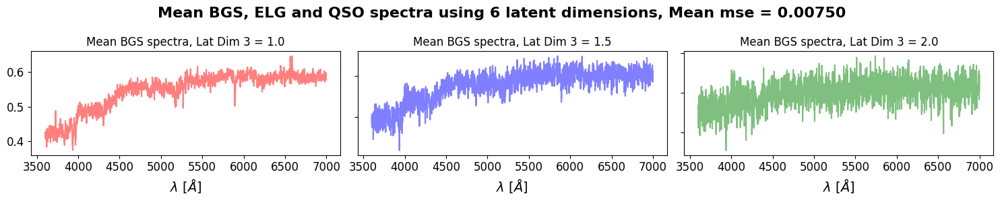

In [71]:

figure, axis = plt.subplots(1, 3, figsize=(15, 3))


axis[0].plot(loaded_restframe_wavelengths, latent_dez_ds_norm_bgs_mean_1_0_spec_r, color = 'red', alpha = 0.5)
axis[0].set_title(f'Mean BGS spectra, Lat Dim 3 = 1.0')

axis[1].plot(loaded_restframe_wavelengths, latent_dez_ds_norm_bgs_mean__1_5_spec_r, color = 'blue', alpha = 0.5)
axis[1].set_title(f'Mean BGS spectra, Lat Dim 3 = 1.5')

axis[2].plot(loaded_restframe_wavelengths, latent_dez_ds_norm_bgs_mean__2_0_spec_r, color = 'green', alpha = 0.5)
axis[2].set_title(f'Mean BGS spectra, Lat Dim 3 = 2.0')
    


for ax in axis.flat:

    ax.set_xlabel('$\lambda$ [$\AA$]', fontsize = 14)
    #ax.set_ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]', fontsize = 8)

# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
figure.suptitle(f'Mean BGS, ELG and QSO spectra using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}',fontweight = 'bold', size =16)
plt.tight_layout()
plt.show()

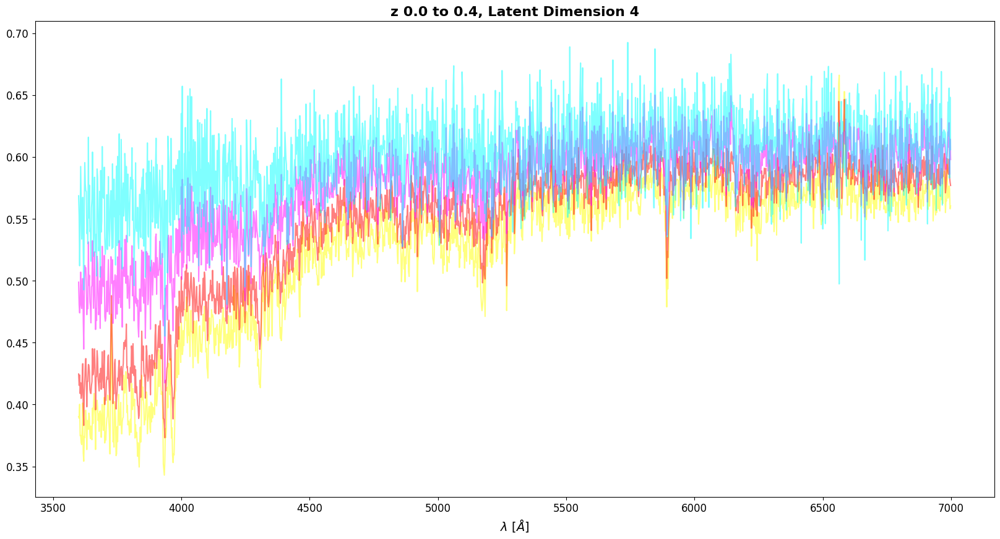

In [72]:
#Plotting these windowed reconstructed spectra

plt.figure(figsize = (20, 10))

plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_bgs_mean_spec_r, color = 'yellow', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_bgs_mean_1_0_spec_r, color = 'red', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_bgs_mean__1_5_spec_r, color = 'magenta', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_bgs_mean__2_0_spec_r, color = 'cyan', alpha = 0.5)

#plt.xlim([5000, 6500])
#plt.ylim([0.3, 0.8])
plt.xlabel('$\lambda$ [$\AA$]')
#plt.ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
plt.title(f'{run_name}, Latent Dimension {lat_d}', fontweight = 'bold', size =16)
plt.show()

# XXXXXXXXXXXXXXXXXXXXXXXXXXXXXX
#  STOP IGNORING
# XXXXXXXXXXXXXXXXXXXXXXXX

## Using Corner Plots to visualise all the dimensions at once

In [121]:
import corner

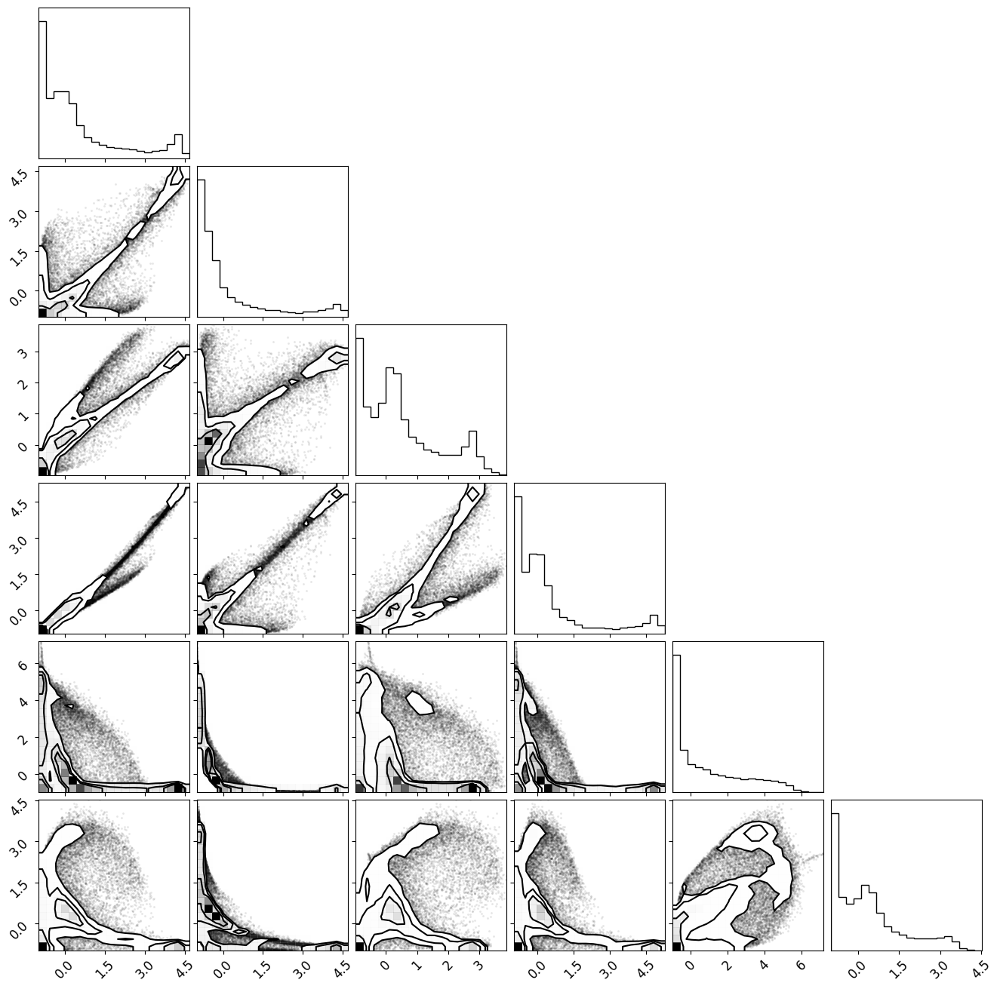

In [122]:
figure = corner.corner(latent_dez_ds_norm)
figure.savefig("corner.png")

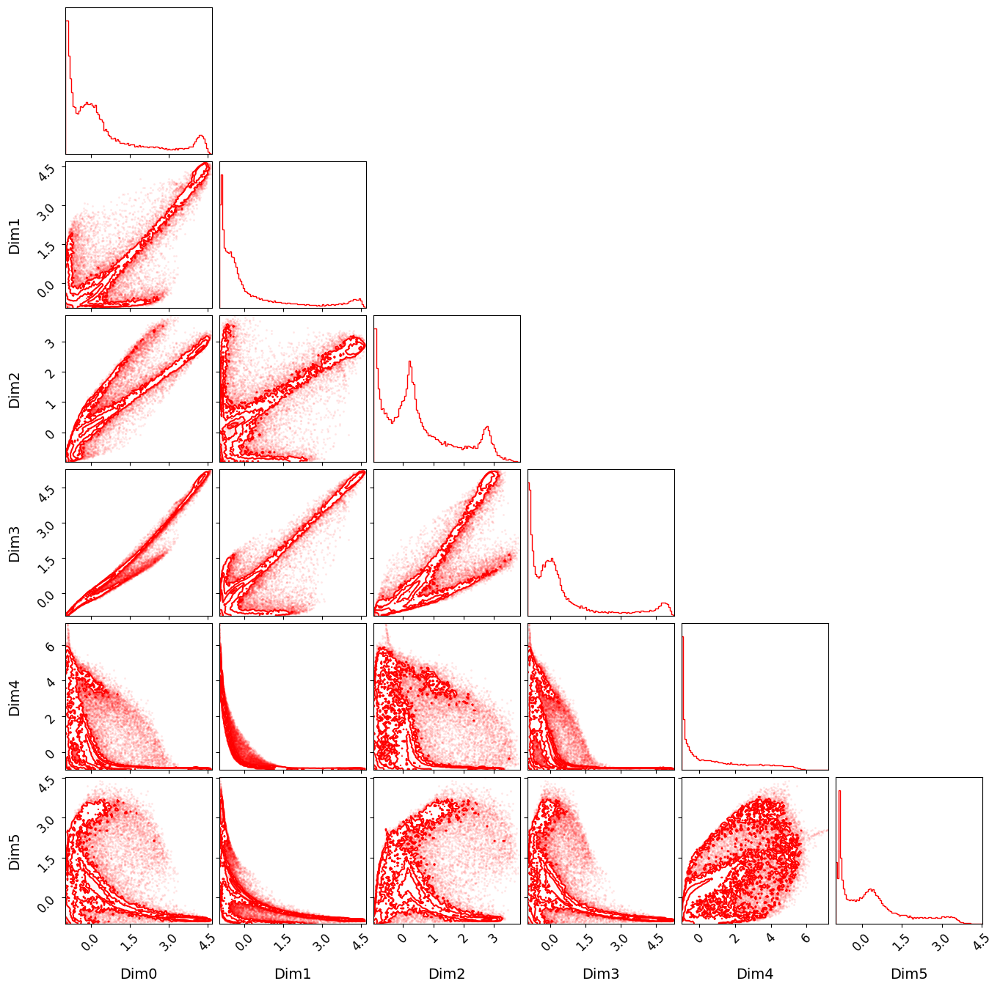

In [123]:
figure = corner.corner(latent_dez_ds_norm, color = 'red', plot_contours = True, bins = 100, alpha = 1, \
                       labels = ['Dim0','Dim1','Dim2','Dim3','Dim4','Dim5'])

### This is all fine. At the moment though there's no way of seeing which of the points are which. The spectra are still in the same order as the from the validation set. Need to split those up. We have already identified the lists of index numbers which are bgs, elg and qso so now we just need to partition the different sets of data into their groups.

In [124]:
latent_dez_ds_norm.shape

(46293, 6)

In [125]:
print(type(latent_dez_ds_norm))

<class 'numpy.ndarray'>


In [126]:
STAR_latent_data = latent_dez_ds_norm[errors_STAR_list,:]
GALAXY_latent_data = latent_dez_ds_norm[errors_GALAXY_list,:]
#QSO_latent_data = latent_dez_ds_norm[errors_QSO_list,:]

print(STAR_latent_data.shape)
print(GALAXY_latent_data.shape)
#print(QSO_latent_data.shape)

(26921, 6)
(19372, 6)


### Here's some code from Datckoverflow to plot multiple corner plots over each other
https://stackoverflow.com/questions/60877259/plot-multiple-datasets-in-the-same-corner-plot

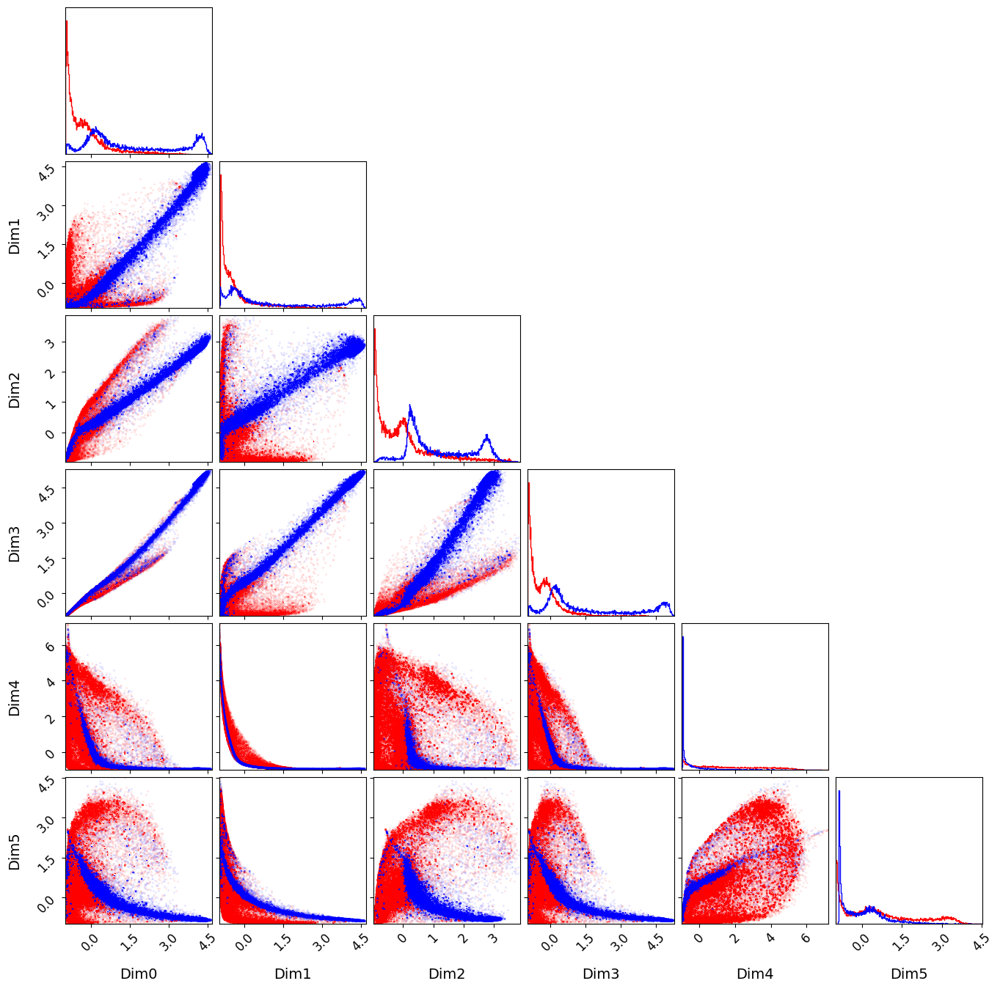

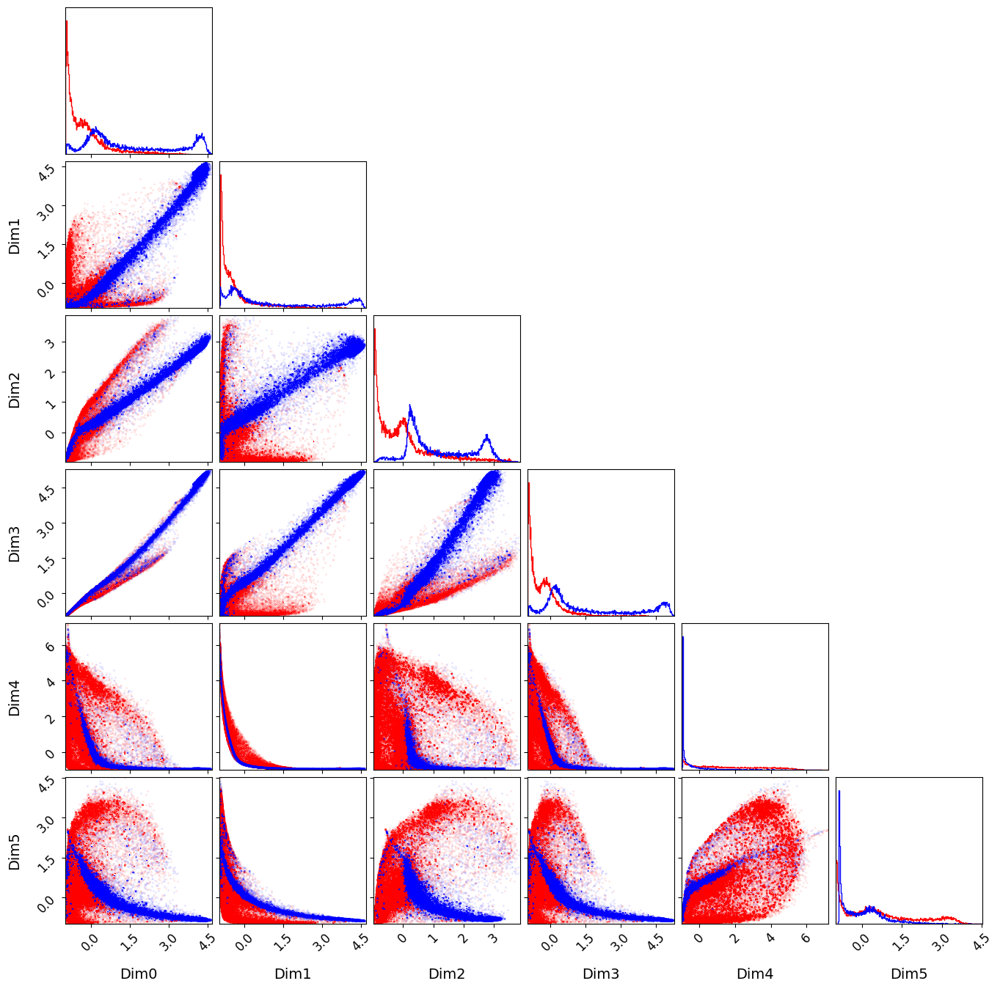

In [127]:
figure = corner.corner(STAR_latent_data, color = 'red', plot_contours = True, bins = 500, alpha = 0.1, \
                       labels = ['Dim0','Dim1','Dim2','Dim3','Dim4','Dim5'])
corner.corner(GALAXY_latent_data,fig=figure, color = 'blue', plot_contours = True, bins = 500, alpha = 0.05)
#corner.corner(QSO_latent_data,fig=figure, color = 'green', plot_contours = True, bins = 500, alpha = 1.0)

## Using TSNE for visualisation
see p643 of Geron

In [94]:
from sklearn.manifold import TSNE

In [95]:
tsne = TSNE(init = 'pca', learning_rate = 'auto', random_state = 42)

In [130]:
X_train_2D = tsne.fit_transform(latent_dez_ds_norm)

In [131]:
X_train_2D.shape

(46293, 2)

<function matplotlib.pyplot.show(close=None, block=None)>

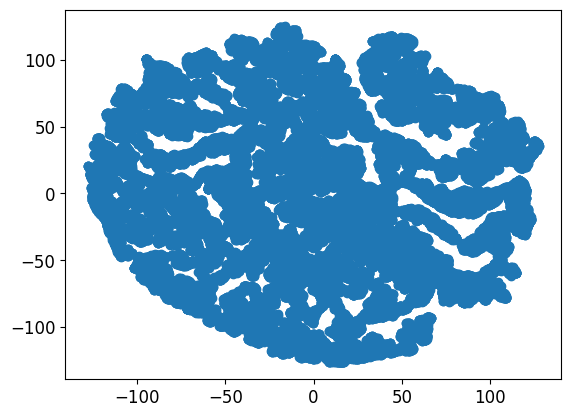

In [132]:
plt.scatter(X_train_2D[:,0], X_train_2D[:,1])
plt.show

## Using the labelling to colour code the output - ASSUMES THAT TSNE PRESERVES THE ORDER OF THE UNDERLYING DATA - NEED TO CHECK THIS TO BE SURE

In [133]:
STAR_X_train_2D = X_train_2D[errors_STAR_list,:]
GALAXY_X_train_2D = X_train_2D[errors_GALAXY_list,:]
#QSO_X_train_2D = X_train_2D[errors_QSO_list,:]

<function matplotlib.pyplot.show(close=None, block=None)>

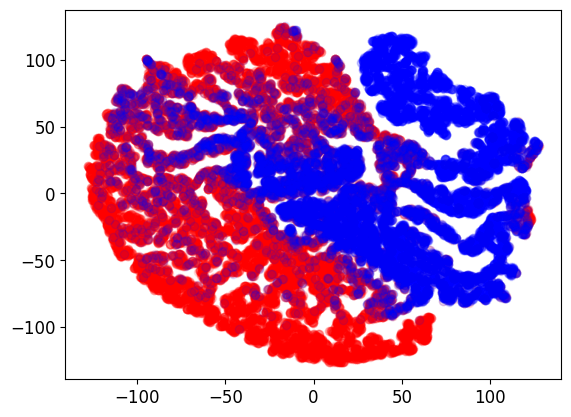

In [134]:
plt.scatter(STAR_X_train_2D[:,0], STAR_X_train_2D[:,1], color = 'red', alpha = 0.1)
plt.scatter(GALAXY_X_train_2D[:,0], GALAXY_X_train_2D[:,1], color = 'blue', alpha = 0.1)
#plt.scatter(QSO_X_train_2D[:,0], QSO_X_train_2D[:,1], color = 'green', alpha = 1.0)
plt.show

In [ ]:
# The bit that's missing here at the moment is looking at which points are most isolated in the latent space

# **********************************************
# THIS IS WHERE THE AUTOENCODER STUFF ENDED

# Now let's do this with PCA

In [39]:
from sklearn.decomposition import PCA

In [40]:
num_ecode_nodes = 6

In [41]:
pca = PCA(n_components = num_ecode_nodes)

In [42]:
X_reduced = pca.fit_transform(X_train_dez_ds_norm)

In [43]:
pca.explained_variance_ratio_

array([0.7569217 , 0.17653012, 0.03233882, 0.00547312, 0.00133063,
       0.00076874])

In [44]:
X_reconstructed = pca.inverse_transform(X_reduced)

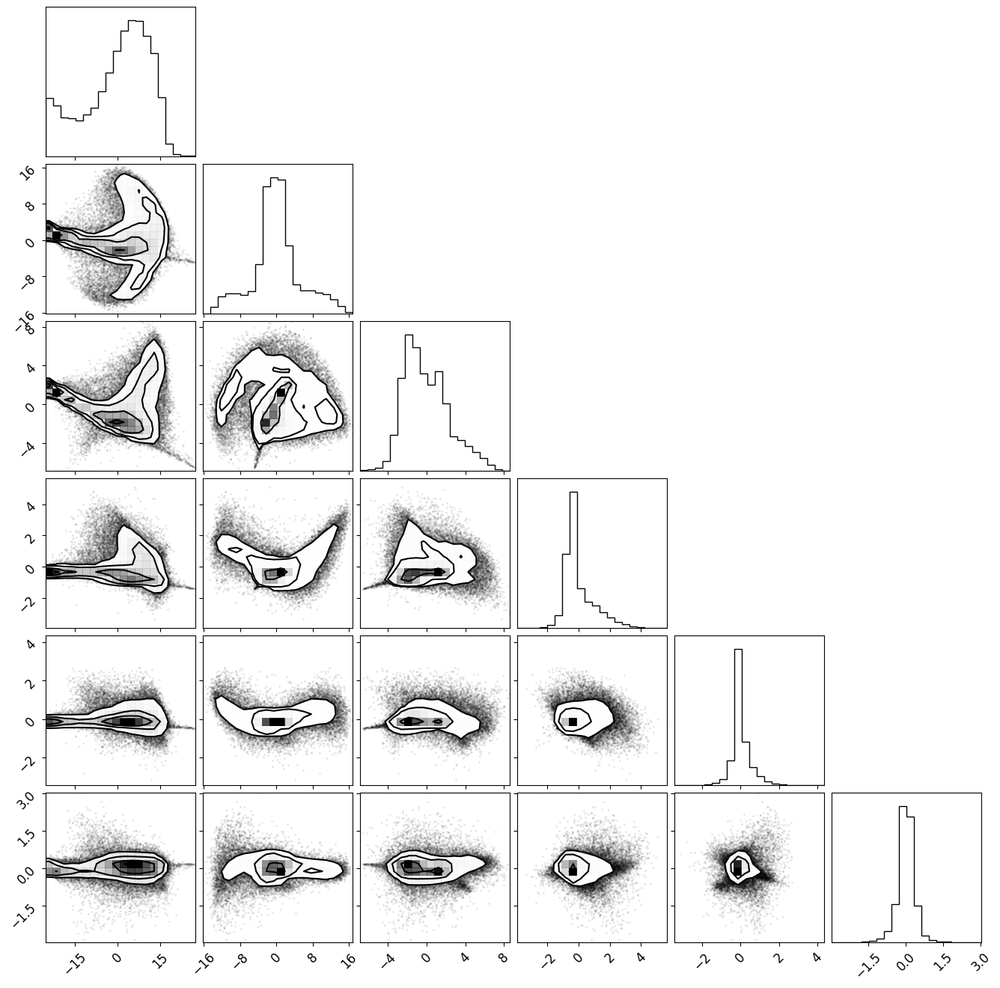

In [45]:
figure = corner.corner(X_reduced)
figure.savefig("corner.png")

In [46]:
spectra_wavelengths_raw = loaded_original_spectra[0][0][6]['brz']

In [47]:
#Adapted to use spectype
errors_STAR_list = []
errors_GALAXY_list = []
errors_QSO_list = []

#This is creating lists with the ID within X_train_ids in it

#for p in range(len(errors)):
for p in range(len(X_train_dez_ds_norm)):
#FOR CHECKING WHETHER INDEXING IS WORKING OK
#for p in range(1):
    i = X_train_ids[p]
    
    if loaded_original_spectra[i][0][4] == 'STAR': 
#        errors_STAR_list.append(i)
        errors_STAR_list.append(p)
    if loaded_original_spectra[i][0][4] == 'GALAXY': 
#        errors_GALAXY_list.append(i)
        errors_GALAXY_list.append(p)
    if loaded_original_spectra[i][0][4] == 'QSO':
#        errors_QSO_list.append(i)
        errors_QSO_list.append(p)

#print(errors_STAR_list)
#print(errors_GALAXY_list)
#print(errors_QSO_list)

In [48]:
STAR_PCA_data = X_reduced[errors_STAR_list,:]
GALAXY_PCA_data = X_reduced[errors_GALAXY_list,:]
#QSO_PCA_data = X_reduced[errors_QSO_list,:]

print(STAR_PCA_data.shape)
print(GALAXY_PCA_data.shape)
#print(QSO_PCA_data.shape)

(26921, 6)
(19372, 6)


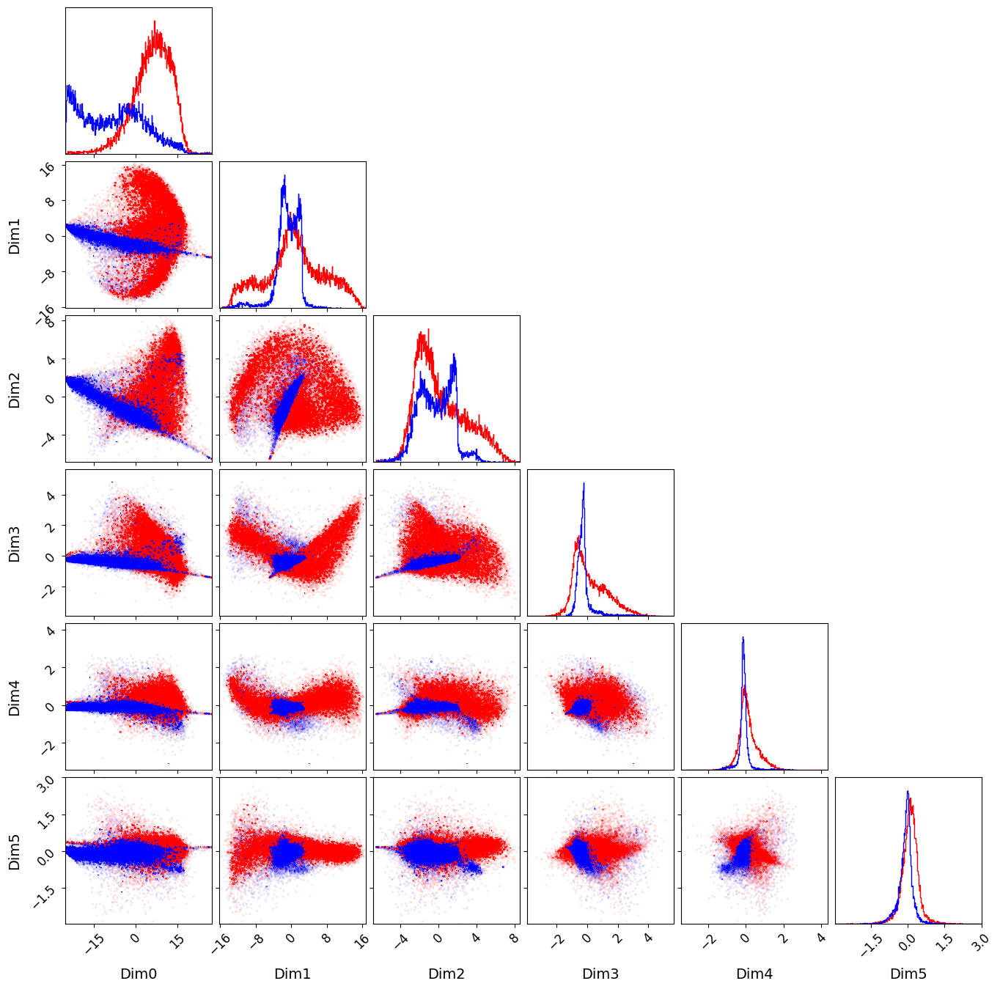

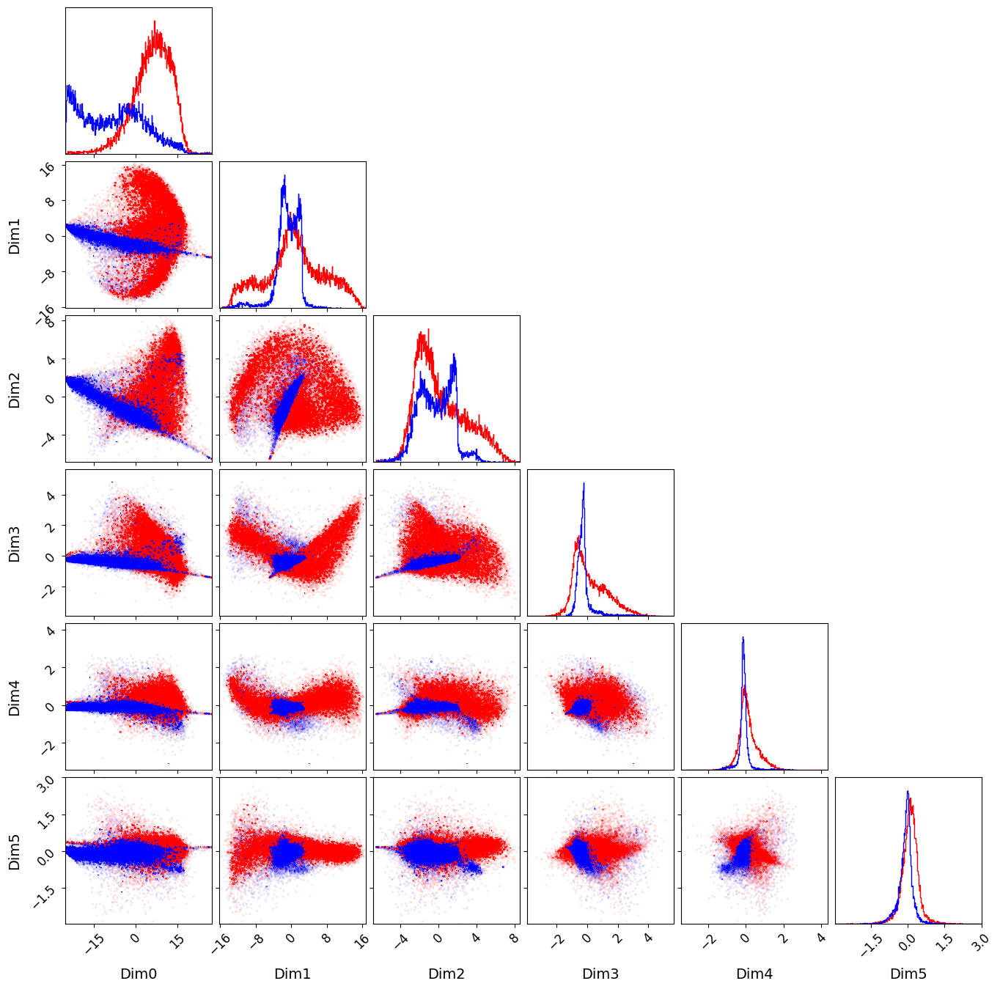

In [49]:
figure = corner.corner(STAR_PCA_data, color = 'red', plot_contours = True, bins = 500, alpha = 0.1, \
                       labels = ['Dim0','Dim1','Dim2','Dim3','Dim4','Dim5'])
corner.corner(GALAXY_PCA_data,fig=figure, color = 'blue', plot_contours = True, bins = 500, alpha = 0.1)
#corner.corner(QSO_latent_data,fig=figure, color = 'green', plot_contours = True, bins = 500, alpha = 1.0)

# Calculating the MSE loss

In [50]:
errors_PCA = []
# loop over all original spectra and their corresponding reconstructions

for i in tqdm(range(len(X_train_dez_ds_norm))):
    # compute the mean squared error between the ground-truth image
    # and the reconstructed image, then add it to our list of errors
    mse = np.mean((X_train_dez_ds_norm[i] - X_reconstructed[i]) ** 2)
    errors_PCA.append(mse)

100%|██████████| 46293/46293 [00:00<00:00, 108277.39it/s]


In [51]:
mean_error_PCA = np.mean(errors_PCA)
mean_error_PCA

0.0015212582597777472

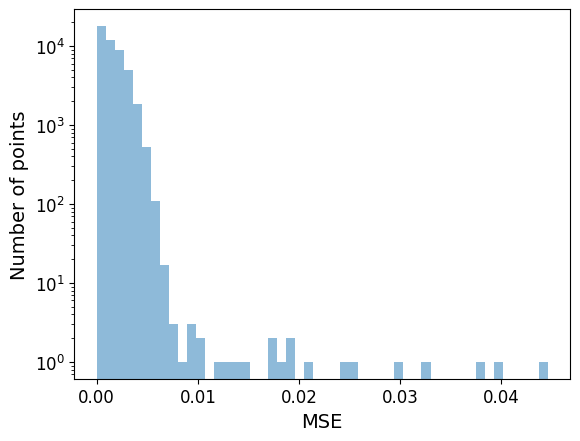

In [52]:
#Note density = False is a good setting as it means that each blob actually ties up with a point
count, bins, ignored = plt.hist(errors_PCA, 50, density=False, alpha=0.5)
plt.yscale('log')
plt.xlabel('MSE')
plt.ylabel('Number of points')
#plt.xlim([0.0,0.09])
#plt.title(f'MSE for {run_name}, {num_ecode_nodes} latent dimensions, MEAN MSE = {mean_error_PCA:.5f}')
plt.show()

In [53]:
# Which ones are over a threshold

indices = np.where(np.array(errors_PCA) > 0.0059)[0].tolist()
print(indices)
print(len(indices))

[317, 1584, 1708, 1841, 5011, 5087, 5473, 5665, 7151, 7460, 7701, 8085, 8563, 8729, 9495, 11346, 11765, 13189, 13209, 13395, 13538, 14817, 16834, 18079, 18919, 19076, 19709, 21202, 21925, 22574, 24020, 24200, 24555, 28241, 29199, 29328, 29839, 31402, 32531, 33156, 33985, 34585, 35571, 35874, 36224, 36249, 37329, 37938, 38391, 38985, 39389, 39573, 40348, 40973, 41055, 41277, 41956, 42278]
58


In [54]:
# Wanting the 3 sigma number of outliers

#Look at 3 sigma
threshold = 1 - 0.9973
print(threshold*len(errors_PCA))

outliers_PCA_indices = np.where(np.array(errors_PCA) > 0.00547)[0].tolist()
#outliers_PCA_indices = np.where(np.array(errors_PCA) > 0.0045)[0].tolist()
#print(outliers_PCA_indices)
print(len(outliers_PCA_indices))

124.99110000000165
125


In [74]:
# Wanting the outlying 1% as anomalies
print(0.01*len(errors_PCA))

outliers_PCA_indices = np.where(np.array(errors_PCA) > 0.004708)[0].tolist()
print(len(outliers_PCA_indices))

462.93
463


In [75]:
# Which ones are below a threshold

indices_best = np.where(np.array(errors_PCA) < 0.000025)[0].tolist()
print(indices_best)

[597, 647, 922, 3981, 5405, 7868, 10506, 12848, 13238, 19875, 19993, 22890, 23527, 23726, 28262, 36706, 38567, 40954, 46095]


In [76]:
int_spec_PCA = [317, 1584, 1708, 1841, 5011, 5087, 5473, 5665, 7151, 7460, 7701, 8085, 8563, 8729, 9495, 11346, 11765, 13189, 13209, 13395, 13538, 14817, 16834, 18079, 18919, 19076, 19709, 21202, 21925, 22574, 24020, 24200, 24555, 28241, 29199, 29328, 29839, 31402, 32531, 33156, 33985, 34585, 35571, 35874, 36224, 36249, 37329, 37938, 38391, 38985, 39389 ]

In [77]:
len(int_spec_PCA)

51

In [78]:
# Worst 500ish - just do this by trial and error

indices_PCA_worst_n = np.where(np.array(errors_PCA) > 0.00466499)[0].tolist()
print(len(indices_PCA_worst_n))

499


In [79]:
errors_PCA_STAR = np.array(errors_PCA)[errors_STAR_list]
errors_PCA_GALAXY = np.array(errors_PCA)[errors_GALAXY_list]
errors_PCA_QSO = np.array(errors_PCA)[errors_QSO_list]

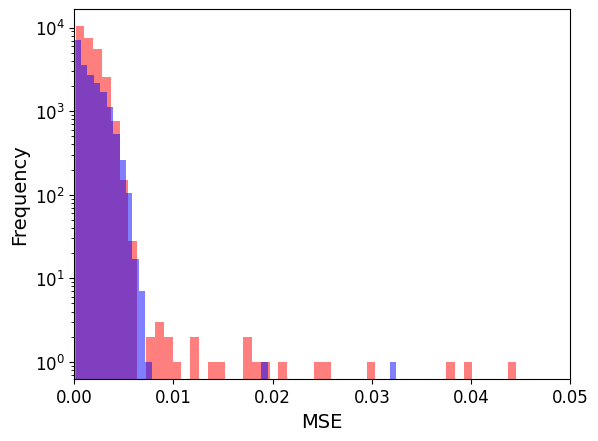

In [80]:
count, bins, ignored = plt.hist(errors_PCA_STAR, 50, density=False, alpha=0.5, color = 'red')
count, bins, ignored = plt.hist(errors_PCA_GALAXY, 50, density=False, alpha=0.5, color = 'blue')
count, bins, ignored = plt.hist(errors_PCA_QSO, 50, density=False, alpha=0.5, color = 'green')

plt.yscale('log')
plt.xlabel('MSE')
plt.ylabel('Frequency')
plt.xlim([0.0,0.05])
#plt.title(f'MSEfor {run_name}, {num_ecode_nodes} latent dimensions')
plt.show()

In [81]:
# Pulling back the Target Ids. If using the validation set then need to use the lines adding the train_size 
#THIS IS AN AREA WHERE WE RELY ON THE ORDER AND HENCE NEED TO BE CAREFUL HOW WE DO THE RANDOMISATION

t_ids_PCA = []
z_vals_PCA = []
spec_types_PCA = []
desi_types_PCA =[]
mse_for_sample_PCA =[]

for p in int_spec_PCA:
    num = X_train_ids[p]
    
    t_ids_PCA.append(loaded_original_spectra[num][0][0])
    #t_ids.append(loaded_original_spectra[train_size+num][0][0])
    z_vals_PCA.append(loaded_original_spectra[num][0][3])
    #z_vals.append(loaded_original_spectra[train_size+num][0][3])
    spec_types_PCA.append(loaded_original_spectra[num][0][4])
    #spec_types.append(loaded_original_spectra[train_size+num][0][4])
    desi_types_PCA.append(loaded_original_spectra[num][1])
    #desi_types.append(loaded_original_spectra[train_size+num][1])
    mse_for_sample_PCA.append(errors_PCA[p])

print(t_ids_PCA)
print(z_vals_PCA)
print(spec_types_PCA)
print(desi_types_PCA)
print(mse_for_sample_PCA)

[39627604730314968, 39627946834527996, 39633113973787134, 39628529800844182, 39628474599605824, 39627949745373274, 39628089898044289, 39628147674587030, 39628033748895762, 39627636275676272, 39633215689851651, 39627999615654020, 39628106620732103, 39628295968391588, 39627860050183252, 39627761647617135, 39628226577827357, 39633462918906214, 39627995840777778, 39627999653404527, 39633134945307799, 39627848356465952, 39633148077672422, 39633438768105386, 39627647105373432, 39627809240390719, 39627975066390970, 39627661252760700, 39633033518645718, 39627685319675891, 39633099436327360, 39633424041903235, 39627606143799650, 39627909463277874, 39628023640625551, 39627678575234075, 39627797391483229, 39627751463849168, 39627751128304246, 39627702709256587, 39633267028133651, 39627821324178851, 39628157111765647, 39628266872505476, 39633435249083486, 39628500625263871, 39627726486766179, 39628112199160339, 39627857370024970, 39627679267295528, 39627666571137176]
[0.01208851000963801, 1.596336

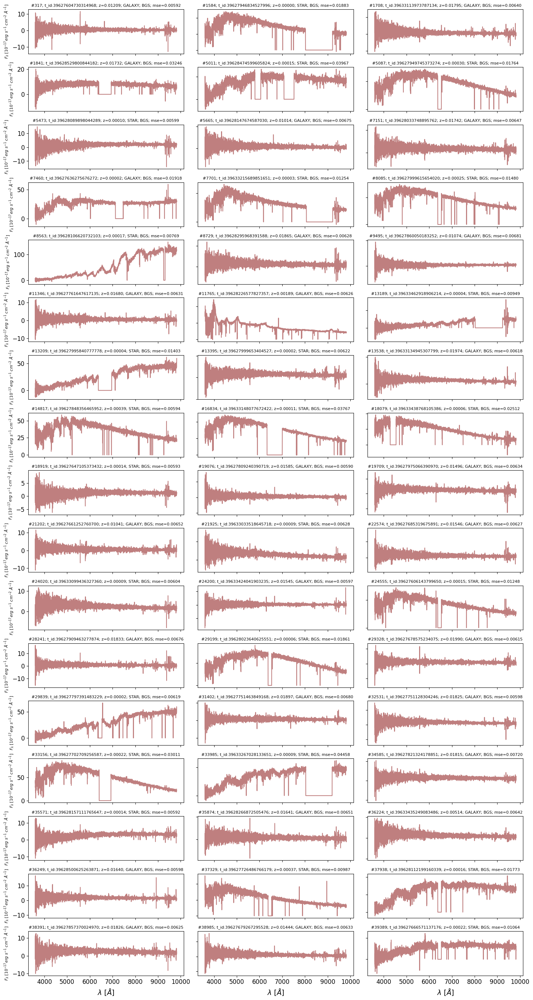

In [82]:
#if using the validation set need to use the version which adds in the train size

#figure, axis = plt.subplots(5, 3, figsize=(15, 12))

#if using 21
#figure, axis = plt.subplots(7, 3, figsize=(15, 18)) #in fig size it is (x, y) width v height

#if using 51
figure, axis = plt.subplots(17, 3, figsize=(15, 28)) #in fig size it is (x, y) width v height


for i in range(len(int_spec_PCA)):
    axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[X_train_ids[int_spec_PCA[i]]][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
#    axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[int_spec[i]][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
    #axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[train_size+int_spec[i]][0][6]['brz'].flatten(), color = 'maroon', alpha = 0.5)
    axis[i // 3, i % 3].set_title(f'#{int_spec_PCA[i]}; t_id:{t_ids_PCA[i]}; z={z_vals_PCA[i]:.5f}; {spec_types_PCA[i]}; {desi_types_PCA[i]}; mse={mse_for_sample_PCA[i]:.5f}', size = 8)
    


for ax in axis.flat:
    #ax.set(xlabel='$\lambda$ [$\AA$]', ylabel=('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
    ax.set_xlabel('$\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]', fontsize = 8)
   


# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
#figure.suptitle(f'Original spectra (8 worst, 7 best (any) and best QSO MSE) sample using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}', fontweight="bold", size =16)

plt.tight_layout()
plt.show()

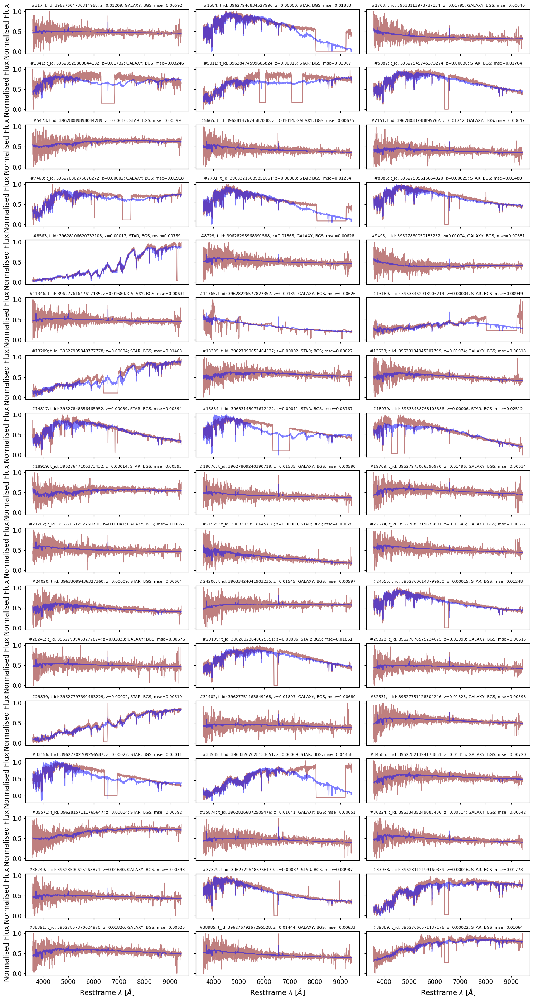

In [83]:
#if using the validation set need to use the version which adds in the train size


#figure, axis = plt.subplots(5, 3, figsize=(15, 12))

#if using 21
#figure, axis = plt.subplots(7, 3, figsize=(15, 18)) #in fig size it is (x, y) width v height

#if using 51
figure, axis = plt.subplots(17, 3, figsize=(15, 28)) #in fig size it is (x, y) width v height


for i in range(len(int_spec_PCA)):
    axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_train_dez_ds_norm[int_spec_PCA[i]], color = 'maroon', alpha = 0.5)
    #axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_valid_dez_ds_norm[int_spec[i]], color = 'maroon', alpha = 0.5)
    
    axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_reconstructed[int_spec_PCA[i]], color = 'blue', alpha = 0.5)
    
    axis[i // 3, i % 3].set_title(f'#{int_spec_PCA[i]}; t_id: {t_ids_PCA[i]}; z={z_vals_PCA[i]:.5f}; {spec_types_PCA[i]}; {desi_types_PCA[i]}; mse={mse_for_sample_PCA[i]:.5f}',  size = 8)

for ax in axis.flat:
    #ax.set(xlabel='$\lambda$ [$\AA$]', ylabel='$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
    ax.set_xlabel('Restframe $\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('Normalised Flux', fontsize = 14)

# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
#figure.suptitle(f'10 worst, 4 best (outright) and best QSO MSE spectra using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}',fontweight = 'bold', size =16)
plt.tight_layout()
plt.show()

# Visualising the mean spectrum for each type

In [66]:
latent_dez_ds_norm_STAR_PCA = X_reduced[errors_STAR_list]
latent_dez_ds_norm_GALAXY_PCA = X_reduced[errors_GALAXY_list]
latent_dez_ds_norm_QSO_PCA = X_reduced[errors_QSO_list]

latent_dez_ds_norm_STAR_mean_PCA = np.mean(latent_dez_ds_norm_STAR_PCA, axis = 0)
latent_dez_ds_norm_GALAXY_mean_PCA = np.mean(latent_dez_ds_norm_GALAXY_PCA, axis = 0)
latent_dez_ds_norm_QSO_mean_PCA = np.mean(latent_dez_ds_norm_QSO_PCA, axis = 0)

print(f'STAR Mean: {latent_dez_ds_norm_STAR_mean_PCA}')
print(f'GALAXY Mean: {latent_dez_ds_norm_GALAXY_mean_PCA}')
print(f'QSO Mean: {latent_dez_ds_norm_QSO_mean_PCA}')

STAR Mean: [5.79066859 0.64511225 0.22568848 0.17751961 0.10171762 0.07376832]
GALAXY Mean: [-8.04721191 -0.89650356 -0.31363615 -0.24669655 -0.14135556 -0.10251481]
QSO Mean: [nan nan nan nan nan nan]


In [67]:
# Need to reshape as the decoder is expecting it to be (1, 6) in shape
latent_dez_ds_norm_STAR_mean_PCA_T = latent_dez_ds_norm_STAR_mean_PCA.reshape(1,num_ecode_nodes)
latent_dez_ds_norm_GALAXY_mean_PCA_T = latent_dez_ds_norm_GALAXY_mean_PCA.reshape(1,num_ecode_nodes)
latent_dez_ds_norm_QSO_mean_PCA_T = latent_dez_ds_norm_QSO_mean_PCA.reshape(1,num_ecode_nodes)

In [68]:
# Let's put these through the decoder to see what the mean spectra look like

latent_dez_ds_norm_STAR_mean_spec_PCA = pca.inverse_transform(latent_dez_ds_norm_STAR_mean_PCA_T)
latent_dez_ds_norm_GALAXY_mean_spec_PCA = pca.inverse_transform(latent_dez_ds_norm_GALAXY_mean_PCA_T)
latent_dez_ds_norm_QSO_mean_spec_PCA = pca.inverse_transform(latent_dez_ds_norm_QSO_mean_PCA_T)

In [69]:
# But these need to be reshaped back again - aaah!
latent_dez_ds_norm_STAR_mean_spec_r_PCA = latent_dez_ds_norm_STAR_mean_spec_PCA.reshape(num_bins)
latent_dez_ds_norm_GALAXY_mean_spec_r_PCA = latent_dez_ds_norm_GALAXY_mean_spec_PCA.reshape(num_bins)
latent_dez_ds_norm_QSO_mean_spec_r_PCA = latent_dez_ds_norm_QSO_mean_spec_PCA.reshape(num_bins)

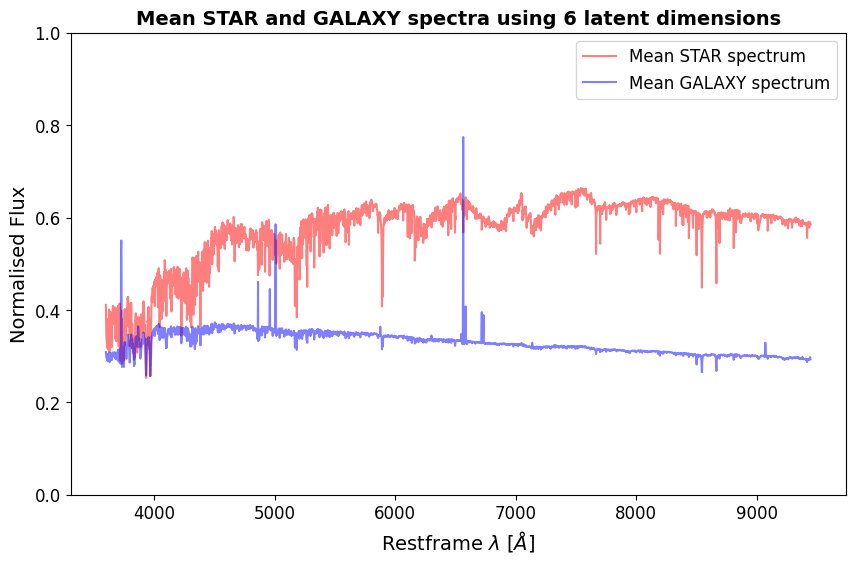

In [70]:
# And low let's also plot all three spectra on the same chart

#Plotting these windowed reconstructed spectra

plt.figure(figsize = (10, 6))

plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_STAR_mean_spec_r_PCA, color = 'red', alpha = 0.5)
plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_GALAXY_mean_spec_r_PCA, color = 'blue', alpha = 0.5)
#plt.plot(loaded_restframe_wavelengths, latent_dez_ds_norm_QSO_mean_spec_r_PCA, color = 'green', alpha = 0.5)

#plt.legend(['Mean STAR spectrum','Mean GALAXY spectrum','Mean QSO spectrum'], fontsize = 20)
plt.legend(['Mean STAR spectrum','Mean GALAXY spectrum'], fontsize = 12)

#plt.xlim([900, 2100])
plt.ylim([0, 1.0])
plt.xlabel('Restframe $\lambda$ [$\AA$]')
plt.ylabel('Normalised Flux')
#plt.title(f'Mean STAR, GALAXY and QSO spectra using {num_ecode_nodes} latent dimensions', fontweight = 'bold', size =16)
plt.title(f'Mean STAR and GALAXY spectra using {num_ecode_nodes} latent dimensions', fontweight = 'bold', size =14)
plt.show()

# **********************
# IMPLEMENTATION OF LOF (remember to cite them)
# ***********************

In [85]:
from sklearn.neighbors import LocalOutlierFactor

In [124]:
#Look at 3 sigma
threshold = 1 - 0.9973
#threshold = 0.0011 #This level gives the 51 worst outliers
print(threshold)

0.0027000000000000357


In [86]:
#OR USE THIS IF YOU WANT OUTERMOST 1percent as outliers
threshold = 0.01

In [87]:
clf = LocalOutlierFactor(n_neighbors=20, contamination = threshold)

In [88]:
y_pred = clf.fit_predict(X_reduced)

In [89]:
n_errors = (y_pred != 1).sum()

In [90]:
print(X_reduced)
print((y_pred))
print(n_errors)

[[ -1.54072159  -0.58641483  -0.35959511  -0.59089845  -0.07121826
    0.30527623]
 [ -5.32305152   2.37209149  -1.39561669  -0.04398946   0.09196561
    0.42543445]
 [  3.49421219 -10.84028861   0.07037515   1.67632833   0.70096008
    0.2065165 ]
 ...
 [-17.05486108   0.90077716   0.58838597  -0.42850162  -0.2503317
   -0.10242362]
 [-12.46040968  -5.3500735   -3.50388718   1.44732589   1.46582826
    0.76856647]
 [-17.23523436   0.54627798   1.37348349  -0.14840004  -0.09621018
   -0.3250312 ]]
[1 1 1 ... 1 1 1]
463


In [91]:
X_scores = clf.negative_outlier_factor_

In [92]:
print(X_scores)

[-1.04884427 -1.05491535 -1.0103885  ... -0.98388261 -1.14202359
 -1.18015675]


In [93]:
indices_LOF = np.where(np.array(y_pred) == -1)[0].tolist()

In [94]:
print(len(indices_LOF))
print(indices_LOF)

463
[66, 75, 150, 299, 539, 746, 1036, 1091, 1272, 1504, 1549, 1584, 1672, 1726, 1756, 1841, 1844, 2129, 2146, 2193, 2214, 2263, 2278, 2433, 2598, 2663, 2740, 2741, 2893, 3058, 3112, 3121, 3164, 3190, 3223, 3535, 3580, 3719, 3745, 3776, 3830, 3833, 3910, 4042, 4199, 4270, 4433, 4518, 4668, 4801, 4891, 4900, 5011, 5336, 5346, 5371, 5377, 5383, 5464, 5495, 5703, 5715, 5749, 5867, 5881, 6052, 6072, 6114, 6141, 6208, 6259, 6429, 6488, 6677, 6817, 6945, 6992, 6997, 7186, 7245, 7298, 7387, 7401, 7460, 7519, 7536, 7555, 7636, 7739, 8244, 8277, 8453, 8832, 8971, 9295, 9331, 9333, 9405, 9447, 9495, 9902, 10134, 10204, 10327, 10377, 10437, 10439, 10613, 10724, 10759, 10864, 10869, 11047, 11474, 11535, 11692, 11865, 11969, 12022, 12058, 12120, 12143, 12398, 12515, 12678, 12867, 12916, 12956, 13099, 13189, 13209, 13226, 13445, 13469, 13616, 13626, 13752, 13817, 13918, 13972, 14001, 14185, 14231, 14304, 14361, 14435, 14532, 14656, 14843, 14920, 15197, 15284, 15390, 15405, 15444, 15573, 15698, 15809

In [101]:
# Just take the worst 51 - these were found by adjusting the concentration factor

int_spec_LOF = [75, 150, 1036, 1549, 1841, 2129, 4900, 5377, 5881, 6488, 7536, 7636, 8453, 8971, 9447, 9495, 12867, 13616, 13817, 15573, 19092, 19944, 20998, 24024, 25006, 26997, 28229, 29525, 32070, 32075, 32684, 32797, 33245, 33295, 33375, 33555, 33985, 34164, 34495, 35570, 36165, 37060, 38397, 38868, 39218, 39382, 40762, 41880, 44641, 45897, 45992]
print(len(int_spec_LOF))

51


In [103]:
# Pulling back the Target Ids. If using the validation set then need to use the lines adding the train_size 
#THIS IS AN AREA WHERE WE RELY ON THE ORDER AND HENCE NEED TO BE CAREFUL HOW WE DO THE RANDOMISATION

t_ids_LOF = []
z_vals_LOF = []
spec_types_LOF = []
desi_types_LOF =[]
mse_for_sample_LOF =[]

for p in int_spec_LOF:
    num = X_train_ids[p]
    
    t_ids_LOF.append(loaded_original_spectra[num][0][0])
    #t_ids.append(loaded_original_spectra[train_size+num][0][0])
    z_vals_LOF.append(loaded_original_spectra[num][0][3])
    #z_vals.append(loaded_original_spectra[train_size+num][0][3])
    spec_types_LOF.append(loaded_original_spectra[num][0][4])
    #spec_types.append(loaded_original_spectra[train_size+num][0][4])
    desi_types_LOF.append(loaded_original_spectra[num][1])
    #desi_types.append(loaded_original_spectra[train_size+num][1])
    mse_for_sample_LOF.append(errors_PCA[p])

print(t_ids_LOF)
print(z_vals_LOF)
print(spec_types_LOF)
print(desi_types_LOF)
print(mse_for_sample_LOF)

[39632991684660205, 39633082260653247, 39633461065023995, 39627745143033256, 39628529800844182, 39627713480232066, 39627931609207764, 39627989213775818, 39628130150777639, 39633054452420730, 39633279564908141, 39633252989800436, 39628391107792349, 39633526018017740, 39628347000489073, 39627860050183252, 39627563139596634, 39627929084232779, 39628285608464817, 39633524440957937, 39633477242457173, 39627943881737628, 39628080746074080, 39633503372968402, 39628268432786216, 39627733713551656, 39633281544620520, 39633113034261676, 39633105610346235, 39633167279196334, 39628245515109187, 39633368391878347, 39627758023740536, 39627665199595572, 39633252985602236, 39633232647425602, 39633267028133651, 39628525099026788, 39627690281539378, 39627841175819994, 39633040284058557, 39627694572312966, 39627847685375564, 39627561604481238, 39633227538761873, 39627769855874637, 39627763254036605, 39627763254037209, 39627725413029982, 39632967106040988, 39627708879078570]
[0.00010353513805561607, 9.350

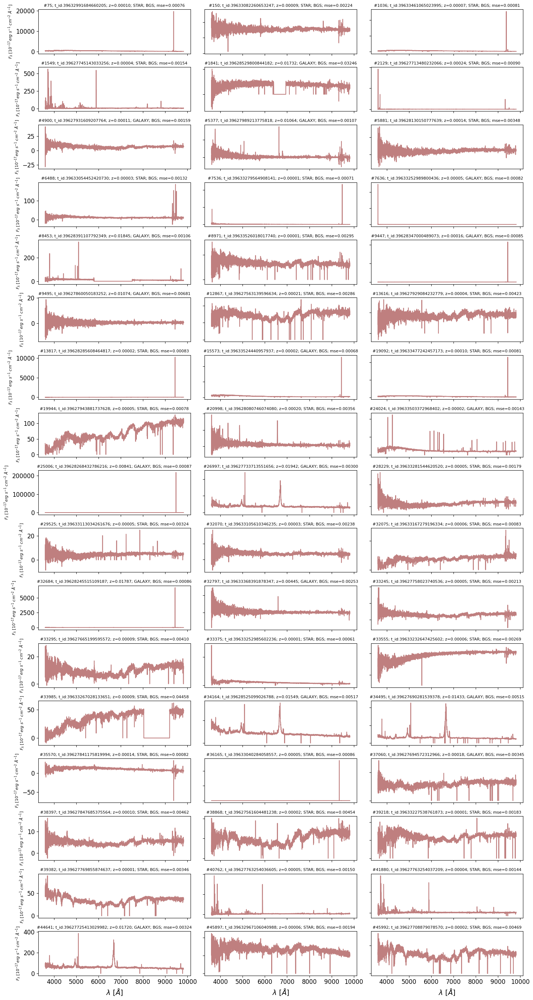

In [104]:
#if using the validation set need to use the version which adds in the train size

#figure, axis = plt.subplots(5, 3, figsize=(15, 12))

#if using 21
#figure, axis = plt.subplots(7, 3, figsize=(15, 18)) #in fig size it is (x, y) width v height

#if using 51
figure, axis = plt.subplots(17, 3, figsize=(15, 28)) #in fig size it is (x, y) width v height


for i in range(len(int_spec_LOF)):
    axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[X_train_ids[int_spec_LOF[i]]][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
#    axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[int_spec[i]][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
    #axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[train_size+int_spec[i]][0][6]['brz'].flatten(), color = 'maroon', alpha = 0.5)
    axis[i // 3, i % 3].set_title(f'#{int_spec_LOF[i]}; t_id:{t_ids_LOF[i]}; z={z_vals_LOF[i]:.5f}; {spec_types_LOF[i]}; {desi_types_LOF[i]}; mse={mse_for_sample_LOF[i]:.5f}', size = 8)
    


for ax in axis.flat:
    #ax.set(xlabel='$\lambda$ [$\AA$]', ylabel=('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
    ax.set_xlabel('$\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]', fontsize = 8)
   


# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
#figure.suptitle(f'Original spectra (8 worst, 7 best (any) and best QSO MSE) sample using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}', fontweight="bold", size =16)

plt.tight_layout()
plt.show()

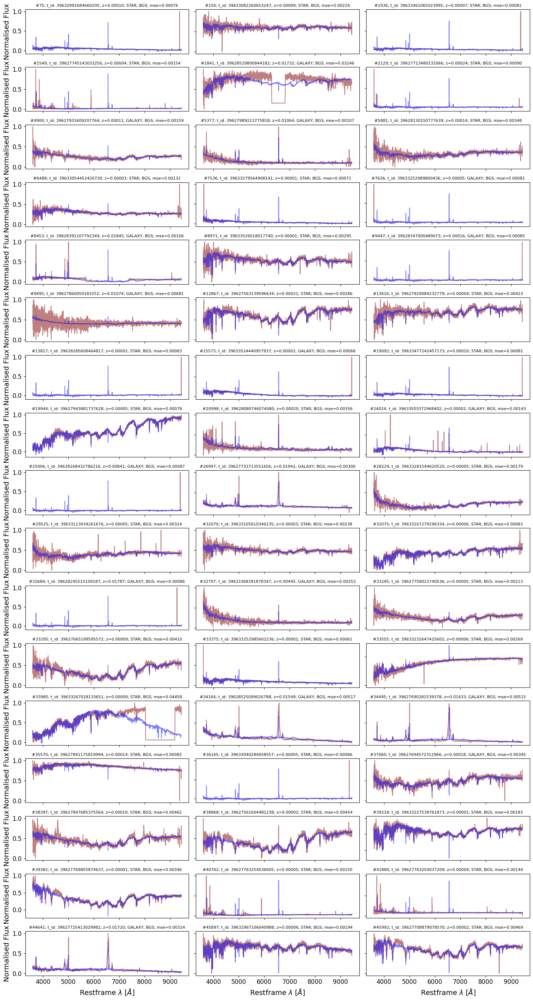

In [105]:
#if using the validation set need to use the version which adds in the train size


#figure, axis = plt.subplots(5, 3, figsize=(15, 12))

#if using 21
#figure, axis = plt.subplots(7, 3, figsize=(15, 18)) #in fig size it is (x, y) width v height

#if using 51
figure, axis = plt.subplots(17, 3, figsize=(15, 28)) #in fig size it is (x, y) width v height


for i in range(len(int_spec_LOF)):
    axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_train_dez_ds_norm[int_spec_LOF[i]], color = 'maroon', alpha = 0.5)
    #axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_valid_dez_ds_norm[int_spec[i]], color = 'maroon', alpha = 0.5)
    
    axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_reconstructed[int_spec_LOF[i]], color = 'blue', alpha = 0.5)
    
    axis[i // 3, i % 3].set_title(f'#{int_spec_LOF[i]}; t_id: {t_ids_LOF[i]}; z={z_vals_LOF[i]:.5f}; {spec_types_LOF[i]}; {desi_types_LOF[i]}; mse={mse_for_sample_LOF[i]:.5f}',  size = 8)

for ax in axis.flat:
    #ax.set(xlabel='$\lambda$ [$\AA$]', ylabel='$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
    ax.set_xlabel('Restframe $\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('Normalised Flux', fontsize = 14)

# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
#figure.suptitle(f'10 worst, 4 best (outright) and best QSO MSE spectra using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}',fontweight = 'bold', size =16)
plt.tight_layout()
plt.show()

### **********************
# END OF IMPLEMENTATION OF LOF
### ***********************

# Let's see how we get on with TSNE

In [95]:
from sklearn.manifold import TSNE

In [96]:
tsne = TSNE(init = 'pca', learning_rate = 'auto', random_state = 42)

In [97]:
X_train_2D_PCA = tsne.fit_transform(X_reduced)

<function matplotlib.pyplot.show(close=None, block=None)>

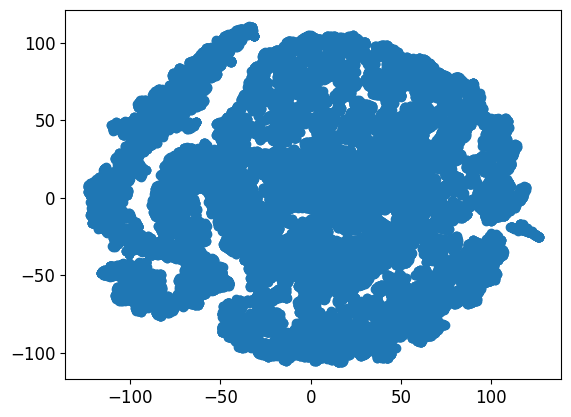

In [98]:
plt.scatter(X_train_2D_PCA[:,0], X_train_2D_PCA[:,1])
plt.show

In [99]:
STAR_X_train_2D_PCA = X_train_2D_PCA[errors_STAR_list,:]
GALAXY_X_train_2D_PCA = X_train_2D_PCA[errors_GALAXY_list,:]
#QSO_X_train_2D_PCA = X_train_2D_PCA[errors_QSO_list,:]

In [100]:
OUTLIERS_LOF_data = X_train_2D_PCA[indices_LOF,:]
OUTLIERS_PCA_data = X_train_2D_PCA[outliers_PCA_indices,:]

print(OUTLIERS_LOF_data.shape)
print(OUTLIERS_PCA_data.shape)

(463, 2)
(463, 2)


<function matplotlib.pyplot.show(close=None, block=None)>

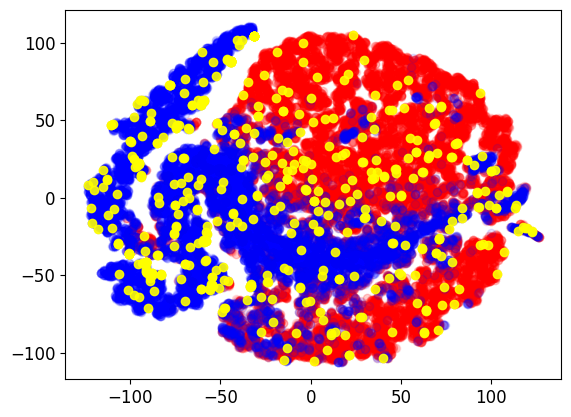

In [103]:
plt.scatter(STAR_X_train_2D_PCA[:,0], STAR_X_train_2D_PCA[:,1], color = 'red', alpha = 0.1)
plt.scatter(GALAXY_X_train_2D_PCA[:,0], GALAXY_X_train_2D_PCA[:,1], color = 'blue', alpha = 0.1)
plt.scatter(OUTLIERS_LOF_data[:,0], OUTLIERS_LOF_data[:,1], color = 'yellow', alpha = 0.9)
#plt.scatter(OUTLIERS_PCA_data[:,0], OUTLIERS_PCA_data[:,1], color = 'cyan', alpha = 0.9)



#plt.scatter(QSO_X_train_2D_PCA[:,0], QSO_X_train_2D_PCA[:,1], color = 'green', alpha = 1.0)
plt.show

In [104]:
# Do this so you can return a method showing the score, which are same and which are different

class Similarity:
    def __init__(self, list1,list2):
        set1 = set(list1)
        set2 = set(list2)
        set_union = set1.union(set2)
    
        list_same =[]
        for i in set1:
            if i in set2:
                list_same.append(i)
        
        set_same = set(list_same)
        
        score = len(set_same)/len(set_union)
        
        
        self.set1 = set1
        self.set2 = set2
        self.union = set_union
        self.same = set_same
        self.score = score

In [105]:
similarity_PCA_LOF = Similarity(indices_LOF,outliers_PCA_indices)

In [106]:
print(len(indices_LOF))

463


In [107]:
print(len(outliers_PCA_indices))

463


In [108]:
similarity_PCA_LOF.score

0.023204419889502764

In [109]:
print(len(similarity_PCA_LOF.set1))

463


In [110]:
print(len(similarity_PCA_LOF.set2))

463


In [111]:
print(len(similarity_PCA_LOF.union))

905


## Want to be able to produce list of DESI IDs for this final so that we have them and can compare them with others
Will want both the combined and also the list of PCA IDs as well

In [116]:
# Pulling back the Target Ids. If using the validation set then need to use the lines adding the train_size 
#THIS IS AN AREA WHERE WE RELY ON THE ORDER AND HENCE NEED TO BE CAREFUL HOW WE DO THE RANDOMISATION

t_ids_union = []
t_IDS_PCA_list = []
t_IDS_LOF_list =[]

for p in similarity_PCA_LOF.union:
    num = X_train_ids[p]
    
    t_ids_union.append(loaded_original_spectra[num][0][0])
    
for p in outliers_PCA_indices:
    num = X_train_ids[p]
    
    t_IDS_PCA_list.append(loaded_original_spectra[num][0][0])
    
for p in indices_LOF:
    num = X_train_ids[p]
    
    t_IDS_LOF_list.append(loaded_original_spectra[num][0][0])       


print(t_ids_union)
print(t_IDS_PCA_list)
print(t_IDS_LOF_list)


[39628127999103266, 39627892673481051, 39633169699308017, 39627592751383011, 39627769260278394, 39627780823979306, 39627624921699073, 39628027537129547, 39627775857918950, 39627683235107171, 39633268273844588, 39633025058734883, 39627611101465813, 39633395407393029, 39627684996713265, 39627925577798877, 39633368391878347, 39627688121468458, 39627685294510869, 39633216528713644, 39633335747608886, 39627593057570664, 39627685319675891, 39633450285667371, 39633237307297617, 39627817721268902, 39627823417135105, 39627409640654739, 39627859580422133, 39633415837847291, 39628212686291164, 39627625055915941, 39627679267295528, 39632991684660205, 39627755632984276, 39627713480232066, 39628302305989038, 39627726860063400, 39628054342934662, 39632936848329957, 39633463447391526, 39627491228261429, 39633348821254536, 39633487463974815, 39627583284841145, 39633386431582211, 39633152490079488, 39632942028293365, 39633472184126062, 39633532103951029, 39633153064700252, 39627921626759813, 39628059325

In [117]:
print(len(t_ids_union))
print(len(t_IDS_PCA_list))
print(len(t_IDS_LOF_list))

905
463
463


In [118]:
# Finally let's save this down so we can use it later
#WARNING
#Keep this commented out and have the file xx to xx to prevent accidental overwriting
#CHECK AND DOUBLE CHECK THAT YOU ARE NOT OVERWRITING EXISTING DATA
afile = open(r'/pscratch/sd/u/ucaprpn/Lists/PCA_LOF_1pc_data_BGS_55293.pkl', 'wb')
bfile = open(r'/pscratch/sd/u/ucaprpn/Lists/PCA_1pc_data_BGS_55293.pkl', 'wb')
cfile = open(r'/pscratch/sd/u/ucaprpn/Lists/LOFusingPCA_1pc_data_BGS_55293.pkl', 'wb')
pickle.dump(t_ids_union, afile)
pickle.dump(t_IDS_PCA_list, bfile)
pickle.dump(t_IDS_LOF_list, cfile)
afile.close()
bfile.close()
cfile.close()

In [120]:
#reload object from file
file2 = open(r'/pscratch/sd/u/ucaprpn/Lists/PCA_LOF_1pc_data_BGS_55293.pkl', 'rb')
file3 = open(r'/pscratch/sd/u/ucaprpn/Lists/PCA_1pc_data_BGS_55293.pkl', 'rb')
file4 = open(r'/pscratch/sd/u/ucaprpn/Lists/LOFusingPCA_1pc_data_BGS_55293.pkl', 'rb')
loaded_list_union = pickle.load(file2)
loaded_list_PCA = pickle.load(file3)
loaded_list_LOF = pickle.load(file4)
file2.close()
file3.close()
file4.close()

In [121]:
print(loaded_list_union)
print(loaded_list_PCA)
print(loaded_list_LOF)

[39628127999103266, 39627892673481051, 39633169699308017, 39627592751383011, 39627769260278394, 39627780823979306, 39627624921699073, 39628027537129547, 39627775857918950, 39627683235107171, 39633268273844588, 39633025058734883, 39627611101465813, 39633395407393029, 39627684996713265, 39627925577798877, 39633368391878347, 39627688121468458, 39627685294510869, 39633216528713644, 39633335747608886, 39627593057570664, 39627685319675891, 39633450285667371, 39633237307297617, 39627817721268902, 39627823417135105, 39627409640654739, 39627859580422133, 39633415837847291, 39628212686291164, 39627625055915941, 39627679267295528, 39632991684660205, 39627755632984276, 39627713480232066, 39628302305989038, 39627726860063400, 39628054342934662, 39632936848329957, 39633463447391526, 39627491228261429, 39633348821254536, 39633487463974815, 39627583284841145, 39633386431582211, 39633152490079488, 39632942028293365, 39633472184126062, 39633532103951029, 39633153064700252, 39627921626759813, 39628059325

# Now moving on to the worst 500 or so to see if running the process again can be helpful

In [179]:
print(len(indices_PCA_worst_n))

499


In [178]:
#Adapted to use spectype
errors_worst_PCA_STAR_list = []
errors_worst_PCA_GALAXY_list = []
errors_worst_PCA_QSO_list = []

#This is creating lists with the ID within X_train_ids in it

for p in range(len(indices_PCA_worst_n)):
#FOR CHECKING WHETHER INDEXING IS WORKING OK
#for p in range(1):
    i = X_train_ids[indices_PCA_worst_n[p]]
    
    if loaded_original_spectra[i][0][4] == 'STAR': 
#        errors_STAR_list.append(i)
        errors_worst_PCA_STAR_list.append(p)
    if loaded_original_spectra[i][0][4] == 'GALAXY': 
#        errors_GALAXY_list.append(i)
        errors_worst_PCA_GALAXY_list.append(p)
    if loaded_original_spectra[i][0][4] == 'QSO':
#        errors_QSO_list.append(i)
        errors_worst_PCA_QSO_list.append(p)

#print(errors_STAR_list)
#print(errors_GALAXY_list)
#print(errors_QSO_list)

In [179]:
print(len(errors_worst_PCA_STAR_list))
print(len(errors_worst_PCA_GALAXY_list))
print(len(errors_worst_PCA_QSO_list))

170
329
0


In [180]:
print(errors_worst_PCA_STAR_list[:10])
print(errors_worst_PCA_GALAXY_list[:10])
print(errors_worst_PCA_QSO_list[:10])

[2, 6, 9, 10, 12, 13, 15, 19, 23, 26]
[0, 1, 3, 4, 5, 7, 8, 11, 14, 16]
[]


In [82]:
errors_worst_PCA_STAR_indices = np.array(indices_PCA_worst_n)[errors_worst_PCA_STAR_list]
errors_worst_PCA_GALAXY_indices = np.array(indices_PCA_worst_n)[errors_worst_PCA_GALAXY_list]
errors_worst_PCA_QSO_indices = np.array(indices_PCA_worst_n)[errors_worst_PCA_QSO_list]

NameError: name 'errors_worst_PCA_STAR_list' is not defined

In [81]:
print(errors_worst_PCA_STAR_indices[:10])
print(errors_worst_PCA_GALAXY_indices[:10])
print(errors_worst_PCA_QSO_indices[:10])

NameError: name 'errors_worst_PCA_STAR_indices' is not defined

# Now we have the indices of the worst n - indices_PCA_worst_n and the breakdown into spectype we can run PCA again

In [191]:
print(X_train_dez_ds_norm[:10])

[[0.16947236 0.29165207 0.65954341 ... 0.09178204 0.54075234 0.40856928]
 [0.13918994 0.59212192 1.         ... 0.48478646 0.35368102 0.44725627]
 [0.77447828 0.39346967 0.71103036 ... 0.42951895 0.31374652 0.26083506]
 ...
 [0.44926158 0.37937097 0.36756826 ... 0.27673916 0.37568571 0.36431119]
 [0.81976376 0.47828379 0.10124891 ... 0.82180403 0.53991962 0.77623592]
 [0.33359214 0.82089342 0.56501604 ... 0.42707694 0.4777805  0.468607  ]]


In [231]:
X_train_dez_ds_norm_worst_PCA = X_train_dez_ds_norm[indices_PCA_worst_n]

In [232]:
print(len(X_train_dez_des_norm_worst_PCA))

499


In [233]:
print(X_train_dez_ds_norm_worst_PCA[0:10])

[[0.42843621 0.48890794 0.76634926 ... 0.56669408 0.59741524 0.54320475]
 [0.11993792 0.26126576 0.60330696 ... 0.48736264 0.45239917 0.47470755]
 [0.88452466 0.29817569 0.50041278 ... 0.24044163 0.43816989 0.37391551]
 ...
 [0.84136902 0.76598726 0.00490396 ... 0.52187989 0.58883859 0.54686267]
 [0.85751612 0.30299393 0.48667495 ... 0.43564738 0.47250176 0.41587782]
 [0.78240811 0.97475159 0.08433542 ... 0.48807174 0.74311062 0.70789933]]


In [234]:
# Now let's do PCA on the outliers

In [235]:
pca = PCA(n_components = 2)

In [236]:
X_reduced_worst_PCA = pca.fit_transform(X_train_dez_ds_norm_worst_PCA)

In [237]:
pca.explained_variance_ratio_

array([0.52268176, 0.13874708])

In [238]:
X_reconstructed_worst_PCA = pca.inverse_transform(X_reduced_worst_PCA)

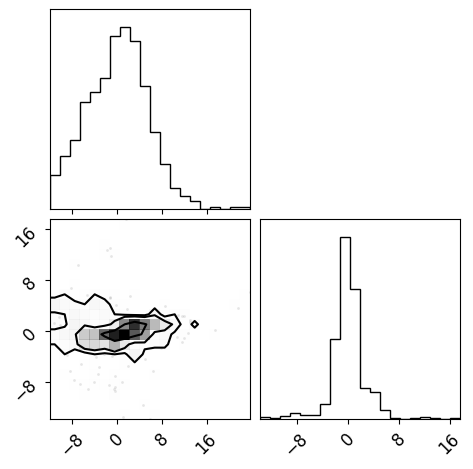

In [239]:
figure = corner.corner(X_reduced_worst_PCA)
figure.savefig("corner.png")

In [240]:
STAR_PCA_worst_data = X_reduced_worst_PCA[errors_worst_PCA_STAR_list,:]
GALAXY_PCA_worst_data = X_reduced_worst_PCA[errors_worst_PCA_GALAXY_list,:]
#QSO_PCA_worst_data = X_reduced_worst_PCA[errors_worst_PCA_QSO_list,:]

print(STAR_PCA_worst_data.shape)
print(GALAXY_PCA_worst_data.shape)
#print(QSO_PCA_worst_data.shape)

(170, 2)
(329, 2)


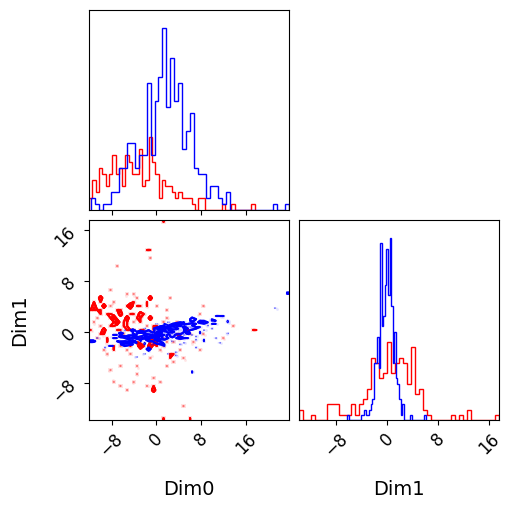

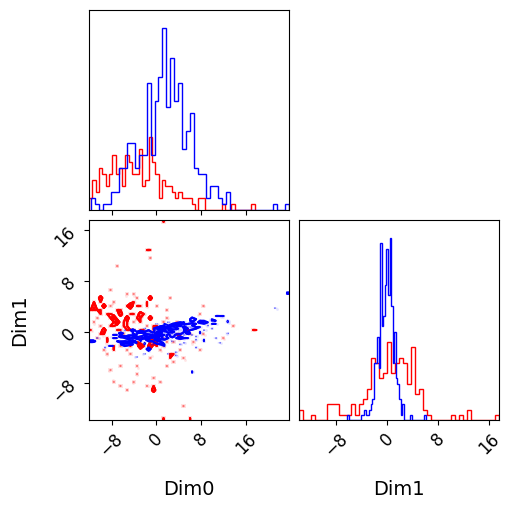

In [246]:
figure = corner.corner(STAR_PCA_worst_data, color = 'red', plot_contours = True, bins = 50, alpha = 0.9, \
                       labels = ['Dim0','Dim1','Dim2','Dim3','Dim4','Dim5'])
corner.corner(GALAXY_PCA_worst_data,fig=figure, color = 'blue', plot_contours = True, bins = 50, alpha = 0.9)
#corner.corner(QSO_PCA_worst_data,fig=figure, color = 'green', plot_contours = True, bins = 500, alpha = 1.0)

# Calculating the MSE loss

In [242]:
errors_PCA_worst = []
# loop over all original spectra and their corresponding reconstructions

for i in tqdm(range(len(X_train_dez_ds_norm_worst_PCA))):
    # compute the mean squared error between the ground-truth image
    # and the reconstructed image, then add it to our list of errors
    mse = np.mean((X_train_dez_ds_norm_worst_PCA[i] - X_reconstructed_worst_PCA[i]) ** 2)
    errors_PCA_worst.append(mse)

100%|██████████| 499/499 [00:00<00:00, 60090.66it/s]


In [247]:
mean_error_PCA_worst = np.mean(errors_PCA_worst)
mean_error_PCA_worst

0.006611025573528379

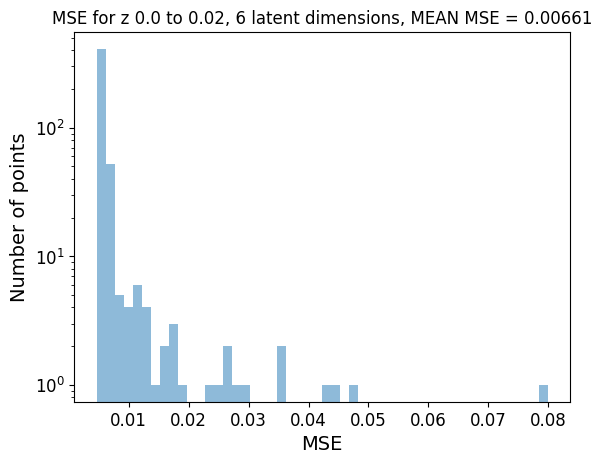

In [248]:
#Note density = False is a good setting as it means that each blob actually ties up with a point
count, bins, ignored = plt.hist(errors_PCA_worst, 50, density=False, alpha=0.5)
plt.yscale('log')
plt.xlabel('MSE')
plt.ylabel('Number of points')
#plt.xlim([0.0,0.09])
plt.title(f'MSE for {run_name}, {num_ecode_nodes} latent dimensions, MEAN MSE = {mean_error_PCA_worst:.5f}')
plt.show()

In [252]:
# Which ones are over a threshold

indices_PCA_worst = np.where(np.array(errors_PCA_worst) > 0.015)[0].tolist()
print(indices_PCA_worst)
print(len(indices_PCA_worst))

[19, 21, 48, 49, 73, 74, 144, 145, 160, 189, 196, 309, 354, 363, 411, 428, 436, 497]
18


In [ ]:
# Pulling back the Target Ids. If using the validation set then need to use the lines adding the train_size 
#THIS IS AN AREA WHERE WE RELY ON THE ORDER AND HENCE NEED TO BE CAREFUL HOW WE DO THE RANDOMISATION

t_ids_PCA = []
z_vals_PCA = []
spec_types_PCA = []
desi_types_PCA =[]
mse_for_sample_PCA =[]

for p in int_spec_PCA:
    num = X_train_ids[p]
    
    t_ids_PCA.append(loaded_original_spectra[num][0][0])
    #t_ids.append(loaded_original_spectra[train_size+num][0][0])
    z_vals_PCA.append(loaded_original_spectra[num][0][3])
    #z_vals.append(loaded_original_spectra[train_size+num][0][3])
    spec_types_PCA.append(loaded_original_spectra[num][0][4])
    #spec_types.append(loaded_original_spectra[train_size+num][0][4])
    desi_types_PCA.append(loaded_original_spectra[num][1])
    #desi_types.append(loaded_original_spectra[train_size+num][1])
    mse_for_sample_PCA.append(errors_PCA[p])

print(t_ids_PCA)
print(z_vals_PCA)
print(spec_types_PCA)
print(desi_types_PCA)
print(mse_for_sample_PCA)

In [ ]:
#if using the validation set need to use the version which adds in the train size

#figure, axis = plt.subplots(5, 3, figsize=(15, 12))

#if using 18
figure, axis = plt.subplots(6, 3, figsize=(15, 15)) #in fig size it is (x, y) width v height

#if using 21
#figure, axis = plt.subplots(7, 3, figsize=(15, 18)) #in fig size it is (x, y) width v height


for i in range(len(int_spec_PCA_worst)):
    axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[X_train_ids[indices_PCA_worst_n[int_spec_PCA_worst[i]]]][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
#    axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[int_spec[i]][0][7]['brz'].flatten(), color = 'maroon', alpha = 0.5)
    #axis[i // 3, i % 3].plot(spectra_wavelengths_raw, loaded_original_spectra[train_size+int_spec[i]][0][6]['brz'].flatten(), color = 'maroon', alpha = 0.5)
    axis[i // 3, i % 3].set_title(f'#{indices_PCA_worst_n[int_spec_PCA_worst[i]]}; t_id:{t_ids_PCA_worst[i]}; z={z_vals_PCA_worst[i]:.5f}; {spec_types_PCA_worst[i]}; {desi_types_PCA_worst[i]}; mse={mse_for_sample_PCA_worst[i]:.5f}', size = 8)
    


for ax in axis.flat:
    #ax.set(xlabel='$\lambda$ [$\AA$]', ylabel=('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
    ax.set_xlabel('$\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]', fontsize = 8)
   


# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
figure.suptitle(f'Original spectra (8 worst, 7 best (any) and best QSO MSE) sample using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}', fontweight="bold", size =16)

plt.tight_layout()
plt.show()

In [ ]:

#figure, axis = plt.subplots(5, 3, figsize=(15, 12))

#if using 18
figure, axis = plt.subplots(6, 3, figsize=(15, 15)) #in fig size it is (x, y) width v height

#if using 21
#figure, axis = plt.subplots(7, 3, figsize=(15, 18)) #in fig size it is (x, y) width v height


for i in range(len(int_spec_PCA_worst)):
    axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_train_dez_ds_norm[indices_PCA_worst_n[int_spec_PCA_worst[i]]], color = 'maroon', alpha = 0.5)
    #axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_valid_dez_ds_norm[int_spec[i]], color = 'maroon', alpha = 0.5)
    
    axis[i // 3, i % 3].plot(loaded_restframe_wavelengths, X_reconstructed[indices_PCA_worst_n[int_spec_PCA_worst[i]]], color = 'blue', alpha = 0.5)
    
    axis[i // 3, i % 3].set_title(f'#{indices_PCA_worst_n[int_spec_PCA_worst[i]]}; t_id: {t_ids_PCA_worst[i]}; z={z_vals_PCA_worst[i]:.5f}; {spec_types_PCA_worst[i]}; {desi_types_PCA_worst[i]}; mse={errors_PCA[indices_PCA_worst_n[int_spec_PCA_worst[i]]]:.5f}',  size = 8)

for ax in axis.flat:
    #ax.set(xlabel='$\lambda$ [$\AA$]', ylabel='$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
    ax.set_xlabel('Restframe $\lambda$ [$\AA$]', fontsize = 14)
    ax.set_ylabel('Normalised Flux', fontsize = 14)

# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axis.flat:
    ax.label_outer()

    
figure.suptitle(f'10 worst, 4 best (outright) and best QSO MSE spectra using {num_ecode_nodes} latent dimensions, Mean mse = {mean_error:.5f}',fontweight = 'bold', size =16)
plt.tight_layout()
plt.show()

In [1]:
print('hello')

hello


In [ ]:
print('hello')